# From a Single Neuron to LLM Reasoning
## A worked, executable textbook in one notebook

**Audience:** a curious beginner who can read a little Python. No calculus, linear algebra, machine learning, or transformer knowledge is assumed.

**The question that organizes this book:** How can multiplying numbers, applying nonlinear functions, and learning from examples eventually produce a system that solves a problem in several steps?

We will build the answer rather than jump to it. You will calculate a neuron by hand, differentiate a loss, train a network, calculate attention, implement automatic differentiation, train a small decoder transformer, and examine reasoning with controlled experiments. The numerical examples and code are original teaching constructions. They are not reproductions of frontier-model internals.

**Scope and scientific honesty.** This book builds toward an advanced working understanding, not a promise that reading one notebook makes somebody an expert researcher. We know exactly how to implement the architectures and learning rules shown here. We have evidence that large models solve many reasoning tasks. We do not have a complete, universally accepted mechanistic account of every reasoning computation in large language models. Whenever we move from an implemented mechanism to an interpretation, we will say so.

**Reproducibility:** all experiments use only Python, NumPy, and Matplotlib. There are no API keys, internet calls, external datasets, or pretrained checkpoints. All data are generated locally. The notebook contains saved outputs from an actual sequential execution. Your timings and last decimals can differ across machines.

**Reading time:** treat this as several study sessions, not one evening's article. Spend time predicting outputs before running cells. The capstone deliberately uses small dimensions so its entire machinery remains inspectable.


## How to use this notebook

1. Install Python 3.10+ and a Jupyter environment, then install `numpy` and `matplotlib` if needed: `python -m pip install jupyterlab numpy matplotlib`. Installation is an environment setup step; no installation command runs automatically inside this notebook.
2. Open the notebook and choose **Restart Kernel and Run All**. On a normal laptop most cells are quick; transformer training can take a few minutes. It uses the CPU and does not require your GPU.
3. Run cells in order. Later cells intentionally reuse earlier definitions. If a name is missing, restart and run from the top.
4. Read the explanation, do the arithmetic, run the code, then change one number. That final step distinguishes recognizing a formula from understanding its behavior.

The code favors explicit operations over library convenience. Our automatic differentiation engine is an educational subset, not a production framework. Our trained model learns a restricted key–value retrieval task, not English and not general reasoning.

### Route map

| Part | Chapters | You will be able to explain |
|---|---|---|
| I. Numerical foundations | 1–6 | Scalars, vectors, matrices, probabilities, one neuron, nonlinear layers |
| II. Learning | 7–12 | Loss, derivatives, backpropagation, gradient descent, generalization |
| III. Language and transformers | 13–22 | Tokens, embeddings, attention, positions, blocks, generation, training |
| IV. Executable capstone | 23–25 | Autodiff, a complete small transformer, controlled evaluation |
| V. Reasoning | 26–35 | Definitions, learned computation, scratchpads, post-training, search, verification, limits |
| VI. Consolidation | 36–39 | Mathematical audit, exercises with answers, glossary, primary sources |

Within the equations, a symbol is introduced before it is used. Display mathematics uses `$$ ... $$`; short inline mathematics uses `$ ... $`, which Jupyter's MathJax renderer supports.


In [1]:
import sys, math, time, itertools, collections
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('All experiments use locally generated data and CPU arithmetic.')


Python: 3.12.14
NumPy: 2.3.5
All experiments use locally generated data and CPU arithmetic.


### A short Python reading guide before the mathematics

You do not need to memorize every programming construct to follow the explanations. The code becomes more advanced gradually. Here are the conventions used throughout:

* `x = 3` assigns a value to a name. It is a program instruction, not a mathematical assertion that must be true for all time. A later line can change `x`.
* `np.array([2., 3.])` creates a NumPy array. A decimal point makes the examples' floating-point intent explicit. `x.shape` tells you the lengths of its axes.
* Python starts indexing at zero: `x[0]` is the first entry, `x[-1]` is the last. `x[:, 1]` selects every row and the second column. A colon means a slice. `ids[:, -1, :]` selects the last position of every sequence and all its feature coordinates.
* `axis=0` refers to the first axis, `axis=-1` to the last. `keepdims=True` leaves an averaged or summed axis present with length 1 so broadcasting stays clear.
* `for step in range(200)` repeats a block for step numbers 0 through 199. Indentation defines the block. A line beginning `#` is a comment.
* `def f(x):` defines a function. `return` gives its result back to the caller. A function can use functions defined earlier; this is why running the notebook in order matters.
* `@` multiplies matrices or computes a dot product; `*` multiplies matching entries with broadcasting. `**` raises values to powers. `x.T` transposes a matrix; `transpose(...)` can reorder more than two axes.
* `assert condition` stops execution if a check fails. These are executable claims about the examples, not decorative comments.
* `np.random.default_rng(seed)` creates a pseudorandom number generator. A seed makes a sequence repeatable within the numerical setup. Randomness is used to initialize weights, sample batches, and split data; these are distinct roles.

The capstone uses a Python **class** to group an array with methods and gradient bookkeeping. `self` means the particular object whose method is running. A small nested function stores a local backward rule together with references to the objects it needs; this is a **closure**. You may first read those cells for the numerical operations and return later to master the software structure.

**A useful debugging habit:** print shapes before inspecting values. If a tensor is intended to mean batch × positions × features, write those axis meanings beside the shape. A valid matrix product can still be semantically wrong if two equal-sized axes were accidentally exchanged.

**A useful learning habit:** when a ten-line cell feels opaque, run it one line at a time and inspect intermediate arrays. The notebook's worked scalar examples provide a numerical reference for the larger vectorized operations.


# Part I — Numbers becoming functions
## 1. What problem does a neural network solve?

Suppose somebody gives us examples of inputs and desired outputs. An input could be two measurements, a photograph, or a sentence. An output could be a number, a category, or a probability distribution over the next token in a sentence.

We want a function that maps an input to a useful output:

$$\hat y=f_\theta(x).$$

Read this as: “our prediction, y-hat, is the result of applying function $f$, configured by parameters $\theta$, to input $x$.” A **parameter** is an adjustable number. The collection $\theta$ can contain three numbers in a toy model or billions in a large model. The hat over $y$ distinguishes a prediction from the desired answer $y$.

There are two different problems here:

* **Representation:** what computations can the chosen function perform for some setting of its parameters?
* **Learning:** how do we find settings that work on examples we care about?

A calculator has arithmetic rules written by a programmer. A neural network usually has its broad computation written by a programmer, but many particular numerical transformations learned from data. Learning is not magic creation of a program from nothing: the architecture, training objective, data, and optimization procedure strongly constrain what can be learned.

Our first example predicts a delivery time from distance. If $x$ is kilometers and $\hat y$ is minutes, a simple model might be

$$\hat y=3x+5.$$

Three minutes per kilometer plus five minutes of preparation. The numbers 3 and 5 are parameters. Learning could adjust them from delivery records. Even this is already a model; it is not yet a deep network.


In [2]:
distance_km = np.array([0., 1., 2., 4.])
prediction_minutes = 3 * distance_km + 5
for x, y in zip(distance_km, prediction_minutes):
    print(f'{x:.0f} km -> {y:.0f} predicted minutes')


0 km -> 5 predicted minutes
1 km -> 8 predicted minutes
2 km -> 11 predicted minutes
4 km -> 17 predicted minutes


## 2. Scalars, vectors, and the meaning of a dot product

A **scalar** is one number: $3$. A **vector** is an ordered collection: $x=[2,3]$. Order matters: if the first entry is distance and the second is package count, swapping entries changes the meaning.

A vector's **dimension** is its number of entries. In $x\in\mathbb R^2$, the symbol $\mathbb R$ means real numbers and the superscript 2 means two coordinates. It does not mean squaring $x$.

A dot product multiplies matching coordinates and adds:

$$w\cdot x=\sum_{i=1}^{d}w_ix_i.$$

Here $i$ is an index, $d$ is the number of coordinates, and $\sum$ means “sum these terms.” If $w=[0.5,-1]$ and $x=[2,3]$, then

$$w\cdot x=(0.5)(2)+(-1)(3)=1-3=-2.$$

A positive weight increases the score when that feature increases. A negative weight decreases it. The magnitude controls sensitivity. These statements describe this linear expression holding other inputs fixed; they are not automatically causal claims about the real world.

Dot products also measure a kind of alignment. If two equal-length vectors point in similar directions, their dot product tends to be positive. Opposing directions tend to give negative values. But raw dot products are affected by length. The **Euclidean norm** is

$$\|x\|=\sqrt{\sum_i x_i^2}.$$

The **cosine similarity**, for nonzero vectors, removes length:

$$\cos(x,w)=\frac{x\cdot w}{\|x\|\|w\|}.$$

Attention will use learned dot products. This numerical alignment idea will return, but the learned coordinates need not have human-readable names.


In [3]:
x = np.array([2., 3.])
w = np.array([0.5, -1.])
print('Coordinate products:', x*w)
print('Dot product:', x @ w)  # @ is matrix multiplication / dot product
print('Norm of x:', np.linalg.norm(x))
print('Cosine similarity:', (x@w)/(np.linalg.norm(x)*np.linalg.norm(w)))
assert np.isclose(x@w, -2.)


Coordinate products: [ 1. -3.]
Dot product: -2.0
Norm of x: 3.605551275463989
Cosine similarity: -0.49613893835683387


## 3. Matrices and batches: several calculations at once

A **matrix** is a rectangular table of numbers. A matrix with 2 rows and 3 columns has shape $(2,3)$. A **tensor** is the general term: scalars have zero axes, vectors one, matrices two, and a batch of sequences of vectors has three.

We will use **row vectors** for examples throughout the notebook. Let $X$ contain one input example per row. Let $W$ contain one neuron's weights per column. Then

$$Z=XW+b.$$

If $X$ has shape $(B,d_{\rm in})$ and $W$ has shape $(d_{\rm in},d_{\rm out})$, their product has shape $(B,d_{\rm out})$. $B$ is the number of examples in a **batch**. The inner dimensions must match. The entry at row $r$, column $j$ is

$$Z_{rj}=\sum_{i=1}^{d_{\rm in}}X_{ri}W_{ij}+b_j.$$

Take

$$X=\begin{bmatrix}2&3\\1&-1\end{bmatrix},\quad
W=\begin{bmatrix}0.5&1\\-1&2\end{bmatrix},\quad b=[0.1,-0.2].$$

For the first example, output 1 is $2(0.5)+3(-1)+0.1=-1.9$ and output 2 is $2(1)+3(2)-0.2=7.8$. For the second example the outputs are $1.6$ and $-1.2$.

NumPy **broadcasts** the vector $b$ across rows: it conceptually adds the same bias vector to every example. Broadcasting is a shape rule, not a learned operation. `*` means coordinatewise multiplication; `@` means dot or matrix multiplication. Confusing them is a common source of bugs.


In [4]:
X = np.array([[2., 3.], [1., -1.]])
W = np.array([[0.5, 1.], [-1., 2.]])
b = np.array([0.1, -0.2])
Z = X @ W + b
print('Shapes:', X.shape, '@', W.shape, '+', b.shape, '=', Z.shape)
print(Z)
assert np.allclose(Z, [[-1.9, 7.8], [1.6, -1.2]])


Shapes: (2, 2) @ (2, 2) + (2,) = (2, 2)
[[-1.9  7.8]
 [ 1.6 -1.2]]


## 4. One neuron: affine score followed by an activation

A common artificial neuron performs two stages:

$$z=\sum_iw_ix_i+b,\qquad a=\phi(z).$$

$z$ is the **preactivation**, $b$ is the **bias**, $\phi$ is the **activation function**, and $a$ is the output or activation. “Affine” means linear transformation plus an offset. Strictly, $wx+b$ is affine rather than linear when $b\ne0$.

With $x=[2,3]$, $w=[0.5,-1]$, and $b=0.1$, we obtain $z=-1.9$. Three common activations behave differently:

$$\operatorname{ReLU}(z)=\max(0,z),$$
$$\sigma(z)=\frac{1}{1+e^{-z}},$$
$$\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.$$

$e\approx2.71828$ is the base of natural exponentials. $e^z$ grows rapidly with $z$ and is always positive. ReLU returns 0 for our negative score. Sigmoid returns approximately 0.1301, a number strictly between 0 and 1. Tanh returns approximately −0.9562, between −1 and 1.

A sigmoid output can parameterize a probability, but it becomes a useful probability estimate only through the data and training objective. Producing a number in $[0,1]$ does not guarantee calibration or truth.

The term “neuron” is an inspiration, not a biological equivalence. This operation is a mathematical unit. It has no feelings, intention, or tiny conceptual understanding of its own.


z: -1.9 ReLU: 0.0 sigmoid: 0.13010847436299786 tanh: -0.9562374581277391


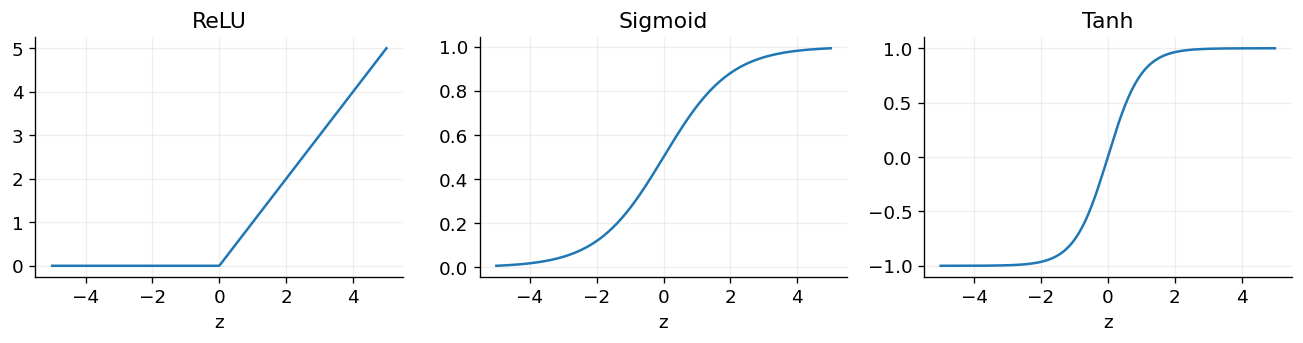

In [5]:
def sigmoid(x):
    # Clipping avoids overflow in this teaching implementation.
    return 1/(1+np.exp(-np.clip(x, -60, 60)))
def relu(x): return np.maximum(x, 0)
z = np.array(-1.9)
print('z:', z, 'ReLU:', relu(z), 'sigmoid:', sigmoid(z), 'tanh:', np.tanh(z))
grid = np.linspace(-5, 5, 300)
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, name, fun in zip(axs, ['ReLU', 'Sigmoid', 'Tanh'], [relu, sigmoid, np.tanh]):
    ax.plot(grid, fun(grid)); ax.set_title(name); ax.set_xlabel('z'); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## 5. Why a stack of linear layers is still linear

Suppose we stack two affine layers without nonlinearities:

$$h=xW_1+b_1,\qquad y=hW_2+b_2.$$

Substitute the first expression into the second:

$$y=x(W_1W_2)+(b_1W_2+b_2).$$

Define $W_*=W_1W_2$ and $b_*=b_1W_2+b_2$. We have just one affine layer, $y=xW_*+b_*$. Adding a thousand such layers does not escape this family of functions. It can change optimization or factorization, but not the fact that the final map is affine.

A nonlinearity breaks this collapse. A ReLU network partitions the input into regions according to which units are active. Inside each region it is affine, but different regions can have different affine rules. That lets the overall boundary bend.

### A numerical example that needs this extra flexibility: XOR

XOR returns 1 if exactly one of two binary inputs is 1:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

No single straight boundary separates the positive diagonal pair from the negative diagonal pair. But two ReLU features suffice on these four inputs:

$$h_1=\operatorname{ReLU}(x_1+x_2),\quad
h_2=\operatorname{ReLU}(x_1+x_2-1),\quad
\hat y=h_1-2h_2.$$

For $(1,1)$, $h_1=2$, $h_2=1$, and $\hat y=0$. For $(0,1)$, $h_1=1$, $h_2=0$, and $\hat y=1$. This is a hand-constructed network, not a trained one. It establishes representability on the specified inputs; learning the parameters is a separate question.


In [6]:
xor_X = np.array([[0.,0.], [0.,1.], [1.,0.], [1.,1.]])
xor_y = np.array([0.,1.,1.,0.])
h1 = relu(xor_X.sum(axis=1))
h2 = relu(xor_X.sum(axis=1)-1)
print(np.column_stack([xor_X, h1, h2, h1-2*h2]))
assert np.allclose(h1-2*h2, xor_y)


[[0. 0. 0. 0. 0.]
 [0. 1. 1. 0. 1.]
 [1. 0. 1. 0. 1.]
 [1. 1. 2. 1. 0.]]


## 6. Depth, width, features, and distributed representation

A **layer** applies a transformation to a collection of activations. A **hidden layer** sits between the raw input and final output. **Width** usually counts the number of hidden coordinates; **depth** counts successive transformations, with conventions varying over whether embeddings and output layers are included.

For a three-layer network in our row-vector convention:

$$h^{(1)}=\phi(xW^{(1)}+b^{(1)}),$$
$$h^{(2)}=\phi(h^{(1)}W^{(2)}+b^{(2)}),$$
$$\hat y=h^{(2)}W^{(3)}+b^{(3)}.$$

Superscripts in parentheses label layers, not powers. Each layer re-expresses the previous representation. Early features can be combined into more complex later features. This is a useful possible organization, not a guarantee that every layer will have a clean “edges, then eyes, then faces” interpretation.

A **feature** is a property represented by the activations. Features can be distributed across many coordinates, and one coordinate can participate in several features. Changing coordinates by rotating a representation can preserve its information while destroying a simple neuron-by-neuron story. Consequently, “neuron 812 is the reasoning neuron” is usually an unjustified simplification.

Why depth? Some compositional functions can be represented much more economically by composing smaller functions than by flattening everything into one enormous shallow expansion. But deeper does not automatically mean better: optimization, data, architecture, and task matter. A universal approximation result establishes the existence of approximations under assumptions; it does not tell us that a specific dataset and optimizer will find them or generalize.

**Checkpoint:** numbers become scores, scores become nonlinear features, and features become inputs to subsequent transformations. We have described what a network can compute. Next we teach it which computation to prefer.


# Part II — How learning changes the numbers
## 7. Loss functions: making “better” numerical

A training example pairs an input $x$ with a desired target $y$. A **loss function** assigns a penalty to prediction error. For one numerical prediction, a convenient loss is

$$L=\frac12(\hat y-y)^2.$$

The factor $1/2$ makes the derivative simpler. If the target is 7 and the model predicts 5, the error is $5-7=-2$ and the loss is $(-2)^2/2=2$. Predicting 8 gives loss $1/2$. Both directions are penalized.

For $N$ examples, the mean loss is

$$\mathcal L(\theta)=\frac1N\sum_{n=1}^N L(f_\theta(x_n),y_n).$$

This objective is sometimes called **empirical risk** because it averages observed training examples. Low training risk is not identical to low future error. A model can memorize the examples, exploit a shortcut, or optimize the wrong target.

Three numerical objects should remain separate:

* **Prediction:** the model's current answer.
* **Loss:** a scalar scoring that answer against training targets.
* **Gradient:** numbers describing local sensitivity of loss to parameters.

For classification we often use a different loss, cross-entropy, which we will derive after probabilities. Choosing a loss means choosing what behavior training rewards. It is part of the problem specification, not merely implementation plumbing.


## 8. Derivatives from first principles

A derivative measures how quickly an output changes with a very small input change. For a scalar function $g$,

$$g'(w)=\lim_{\epsilon\to0}\frac{g(w+\epsilon)-g(w)}{\epsilon}.$$

$\epsilon$ is a small displacement and the limit asks what slope the ratio approaches. You can approximate it numerically; calculus gives exact symbolic expressions for many functions. For example, expanding $(w+\epsilon)^2-w^2=2w\epsilon+\epsilon^2$ and dividing by $\epsilon$ gives $2w+\epsilon$, which tends to $2w$. Thus $d(w^2)/dw=2w$.

For $\hat y=wx+b$ and $L=(\hat y-y)^2/2$, use the **chain rule**:

$$\frac{\partial L}{\partial w}=
\frac{\partial L}{\partial\hat y}\frac{\partial\hat y}{\partial w}
=(\hat y-y)x,$$
$$\frac{\partial L}{\partial b}=\hat y-y.$$

The partial derivative symbol $\partial$ means “vary this argument while holding the others fixed.” The chain rule multiplies sensitivities along a composed path: the effect of $w$ on prediction times the effect of prediction on loss.

At $x=2$, $y=7$, $w=2$, $b=1$, the prediction is 5 and error is −2. Therefore $\partial L/\partial w=-4$ and $\partial L/\partial b=-2$. Increasing $w$ a little decreases the loss locally because the derivative is negative. A derivative is a local statement; it is not a promise about an enormous jump.


In [7]:
def scalar_loss(w, b, x=2., y=7.): return .5*(w*x+b-y)**2
w0, b0, eps = 2., 1., 1e-5
numeric_dw = (scalar_loss(w0+eps,b0)-scalar_loss(w0-eps,b0))/(2*eps)
numeric_db = (scalar_loss(w0,b0+eps)-scalar_loss(w0,b0-eps))/(2*eps)
print('Analytic gradient:', [-4., -2.])
print('Central finite difference:', [numeric_dw, numeric_db])
assert np.allclose([numeric_dw,numeric_db], [-4.,-2.])


Analytic gradient: [-4.0, -2.0]
Central finite difference: [-4.000000000026205, -1.9999999999242843]


## 9. Gradient descent: a complete update by hand

Collect all parameter derivatives into a **gradient**, $\nabla_\theta\mathcal L$. Gradient descent moves opposite that vector:

$$\theta_{\rm new}=\theta_{\rm old}-\eta\nabla_\theta\mathcal L.$$

$\eta$ (eta) is the positive **learning rate**. It controls step size. With $\eta=0.1$ in the preceding example:

$$w_{\rm new}=2-0.1(-4)=2.4,$$
$$b_{\rm new}=1-0.1(-2)=1.2.$$

The new prediction is $2.4(2)+1.2=6$, so loss falls from 2 to $0.5$. The code checks this. If we used $\eta=1$, the parameters would become $w=6,b=3$, prediction 15, and loss 32. A direction can be locally helpful while a large step in it is harmful.

**Training loop:** compute predictions, compute loss, calculate gradients, update parameters, repeat. One update is a **step**. An **epoch** is one pass through a finite training dataset; it is not synonymous with a step. A **minibatch** uses a subset of examples for each step, trading an approximate gradient for lower cost. Stochastic gradient descent uses such noisy estimates; “stochastic” refers to randomness.

No part of this basic loop requires the network to consciously notice an error. The loss and gradient calculations are external training machinery. During ordinary inference the weights are held fixed, unless the system explicitly implements online learning or adaptation.


eta=0.1: w=2.4, b=1.2, loss=0.500
eta=1.0: w=6.0, b=3.0, loss=32.000
Learned slope and intercept: 2.988146268354586 4.91854826305129


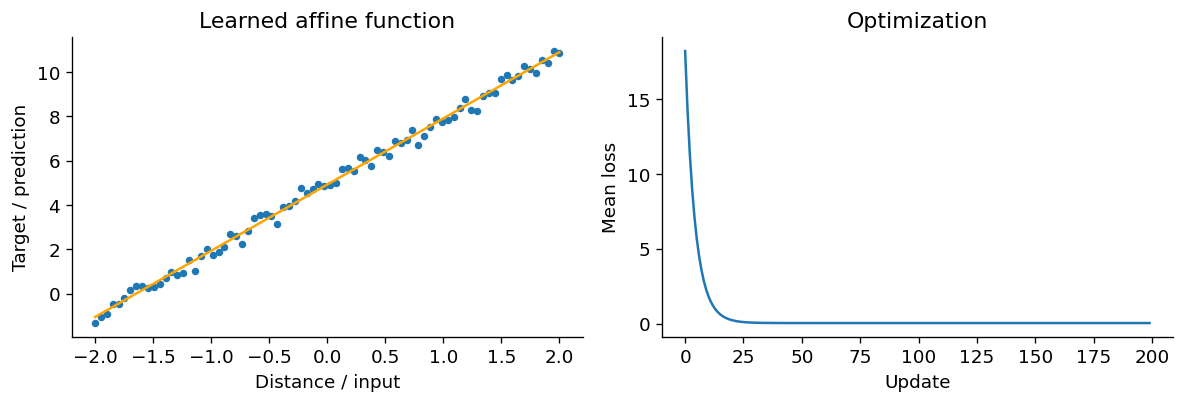

In [8]:
for eta in [.1, 1.]:
    new_w, new_b = w0-eta*(-4), b0-eta*(-2)
    print(f'eta={eta}: w={new_w}, b={new_b}, loss={scalar_loss(new_w,new_b):.3f}')
rng = np.random.default_rng(10)
reg_x = np.linspace(-2, 2, 80)
reg_y = 3*reg_x+5+rng.normal(0,.3,len(reg_x))
rw, rb = 0., 0.
reg_losses=[]
for step in range(200):
    err = rw*reg_x+rb-reg_y
    reg_losses.append(np.mean(err**2)/2)
    rw -= .1*np.mean(err*reg_x)
    rb -= .1*np.mean(err)
print('Learned slope and intercept:', rw, rb)
fig, axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].scatter(reg_x,reg_y,s=12); axs[0].plot(reg_x,rw*reg_x+rb,color='orange')
axs[0].set(xlabel='Distance / input',ylabel='Target / prediction',title='Learned affine function')
axs[1].plot(reg_losses); axs[1].set(xlabel='Update',ylabel='Mean loss',title='Optimization')
plt.tight_layout(); plt.show()


## 10. Backpropagation: assigning credit through hidden layers

**Backpropagation** is an efficient application of the chain rule through a computational graph. Nodes are operations and arrows represent dependence. It calculates gradients; the optimizer uses them. Backpropagation and gradient descent are different algorithms with complementary jobs.

Consider one hidden sigmoid and one linear output:

$$z=w_1x+b_1,\quad h=\sigma(z),\quad \hat y=w_2h+b_2,\quad L=\frac12(\hat y-y)^2.$$

The local derivative of sigmoid is $\sigma'(z)=\sigma(z)(1-\sigma(z))$. Work backward, storing intermediate sensitivities:

$$\delta_{\rm out}=\hat y-y,$$
$$\frac{\partial L}{\partial w_2}=\delta_{\rm out}h,\qquad
\frac{\partial L}{\partial b_2}=\delta_{\rm out},$$
$$\delta_z=\delta_{\rm out}w_2h(1-h),$$
$$\frac{\partial L}{\partial w_1}=\delta_zx,\qquad
\frac{\partial L}{\partial b_1}=\delta_z.$$

For $x=1,y=1,w_1=0,b_1=0,w_2=2,b_2=0$, we get $h=0.5$, prediction 1, error 0, and every gradient 0. Change the target to 2: error is −1, output weight gradient −0.5, and hidden preactivation gradient $(-1)(2)(0.5)(0.5)=-0.5$. Thus hidden weight and bias gradients are both −0.5.

The hidden unit never receives a label saying what feature it should mean. It receives a gradient indicating how changing its output would affect the final objective. This is the numerical **credit assignment** mechanism.

When a value influences the loss through several paths, its gradient contributions **add**. Multiplication along paths and addition across paths are the core bookkeeping rules. In deeper networks, repeated multiplication by small derivatives can shrink gradients; large derivatives can amplify them. These are vanishing and exploding gradient problems.


In [9]:
x, target = 1., 2.
w1,b1,w2,b2 = 0.,0.,2.,0.
h=sigmoid(w1*x+b1); prediction=w2*h+b2
dout=prediction-target; dz=dout*w2*h*(1-h)
analytic=np.array([dz*x,dz,dout*h,dout])
def two_layer_loss(p):
    a,c,d,e=p
    return .5*(d*sigmoid(a*x+c)+e-target)**2
p=np.array([w1,b1,w2,b2],dtype=float)
num=[]
for i in range(len(p)):
    delta=np.zeros_like(p); delta[i]=1e-5
    num.append((two_layer_loss(p+delta)-two_layer_loss(p-delta))/(2e-5))
print('Gradients [w1,b1,w2,b2]:', analytic)
print('Finite differences:', np.array(num))
assert np.allclose(analytic,num)


Gradients [w1,b1,w2,b2]: [-0.5 -0.5 -0.5 -1. ]
Finite differences: [-0.5 -0.5 -0.5 -1. ]


### 10.1 The same backpropagation in matrix form

For $H=\tanh(XW_1+b_1)$ and $\hat Y=HW_2+b_2$, let $G=\partial L/\partial\hat Y$ be the upstream gradient. Then

$$\frac{\partial L}{\partial W_2}=H^\top G,\qquad
\frac{\partial L}{\partial H}=GW_2^\top,$$
$$D=(GW_2^\top)\odot(1-H\odot H),$$
$$\frac{\partial L}{\partial W_1}=X^\top D.$$

$\top$ means transpose: exchange rows and columns. $\odot$ means elementwise multiplication. Bias gradients sum $G$ or $D$ across examples, because the same bias influenced every row. The derivative of tanh is $1-\tanh^2(z)$.

Why the transpose? In a single entry, $\hat Y_{nj}=\sum_kH_{nk}(W_2)_{kj}$. Differentiating with respect to $(W_2)_{kj}$ leaves $H_{nk}$; summing contributions over examples produces $\sum_n H_{nk}G_{nj}$, which is exactly $(H^\top G)_{kj}$. Matrix calculus is ordinary scalar calculus arranged efficiently.

**Shape audit:** if $X$ is $(B,2)$, $W_1$ is $(2,8)$, $H$ is $(B,8)$, $W_2$ is $(8,1)$, and $G$ is $(B,1)$, then $H^\top G$ is $(8,1)$, precisely the shape of $W_2$. A gradient with respect to a parameter must have that parameter's shape.


## 11. Probabilities, softmax, and cross-entropy

A probability distribution over mutually exclusive outcomes assigns nonnegative values summing to 1. A classifier first produces unrestricted scores called **logits**. For logits $z_1,\ldots,z_C$, softmax defines

$$p_i=\frac{e^{z_i}}{\sum_{j=1}^Ce^{z_j}}.$$

For logits $[2,1,0]$, exponentials are approximately $[7.389,2.718,1]$, their sum is 11.107, and probabilities are $[0.6652,0.2447,0.0900]$. Higher logits receive higher probability. Adding the same number to every logit changes nothing, since numerator and denominator get the same multiplicative factor.

For numerical stability we therefore subtract the maximum before exponentiating. This prevents enormous positive exponentials while preserving the distribution.

If the correct class is $k$, the negative log-likelihood loss is

$$L=-\log p_k.$$

$\log$ means natural logarithm, the inverse of the exponential: $\log(e^z)=z$. If the correct class gets probability 0.9, loss is approximately 0.105; at 0.1, loss is approximately 2.303. Being confidently wrong is strongly penalized. The word **cross-entropy** generalizes this to a target distribution $q$: $-\sum_iq_i\log p_i$. A **one-hot** target puts 1 at the correct class and 0 elsewhere, reducing to $-\log p_k$.

An important simplification follows from differentiating the combined softmax and loss:

$$\frac{\partial L}{\partial z_i}=p_i-\mathbf1[i=k].$$

$\mathbf1[\cdot]$ equals 1 when its condition holds and 0 otherwise. Training increases the correct class's logit and decreases others, in proportion to these errors. Across a batch, divide by batch size when the loss is a mean.


In [10]:
def softmax(z, axis=-1):
    e=np.exp(z-np.max(z,axis=axis,keepdims=True))
    return e/e.sum(axis=axis,keepdims=True)
logits=np.array([2.,1.,0.]); probs=softmax(logits)
print('Probabilities:',probs, 'sum:',probs.sum())
print('If class 1 (the second entry) is correct, loss:',-np.log(probs[1]))
grad=probs.copy(); grad[1]-=1
print('Logit gradient:',grad)
assert np.allclose(softmax(logits+10000),probs)


Probabilities: [0.6652 0.2447 0.09  ] sum: 0.9999999999999999
If class 1 (the second entry) is correct, loss: 1.4076059644443804
Logit gradient: [ 0.6652 -0.7553  0.09  ]


### 11.1 Train XOR instead of hand-coding its weights

We now train a two-input, eight-hidden-unit, one-output network. Hidden activations use tanh, and the output sigmoid gives $p=P(y=1\mid x)$. **Binary cross-entropy** is

$$L=-\frac1B\sum_n[y_n\log p_n+(1-y_n)\log(1-p_n)].$$

For a sigmoid output, the derivative with respect to its input logit simplifies to $(p_n-y_n)/B$. The following training loop applies the matrix derivatives above. Random initialization breaks symmetry: if all hidden units began with identical weights, identical gradients could keep them identical.

Read the code in two halves. The forward pass produces hidden features and probabilities. The backward pass obtains every gradient **before** changing any weight. Updating $W_2$ before computing the hidden gradient would accidentally use a different network's parameters.

This dataset has four examples and no meaningful independent test set. Success proves the optimizer found a function matching four labels. It does not prove general intelligence or establish generalization to a new kind of task.


Inputs | target | learned probability
[[0.     0.     0.     0.0004]
 [0.     1.     1.     0.9991]
 [1.     0.     1.     0.9991]
 [1.     1.     0.     0.0011]]


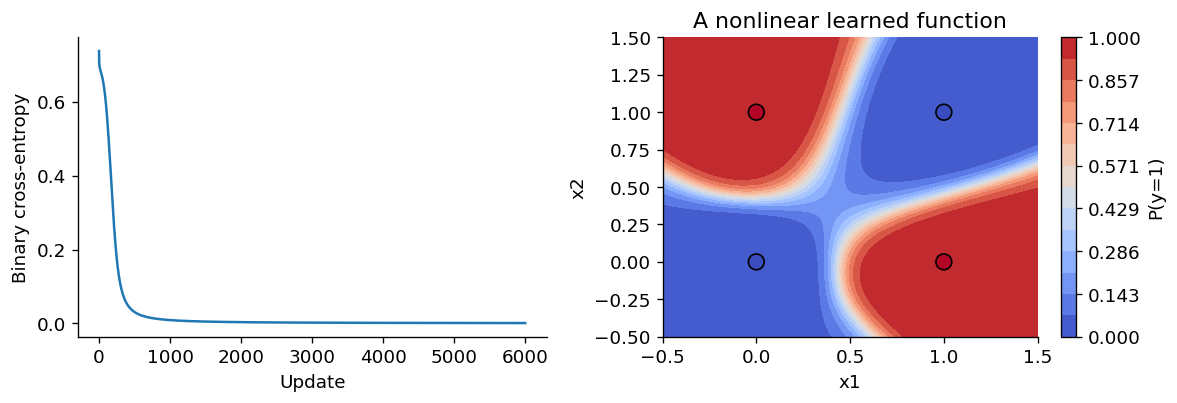

In [11]:
rng=np.random.default_rng(7)
mlp_W1=rng.normal(0,.6,(2,8)); mlp_b1=np.zeros((1,8))
mlp_W2=rng.normal(0,.6,(8,1)); mlp_b2=np.zeros((1,1))
Y=xor_y[:,None]; mlp_losses=[]
for step in range(6000):
    H=np.tanh(xor_X@mlp_W1+mlp_b1)
    P=sigmoid(H@mlp_W2+mlp_b2)
    loss=-np.mean(Y*np.log(P+1e-12)+(1-Y)*np.log(1-P+1e-12))
    mlp_losses.append(loss)
    G=(P-Y)/len(Y)
    dW2=H.T@G; db2=G.sum(axis=0,keepdims=True)
    D=(G@mlp_W2.T)*(1-H**2)
    dW1=xor_X.T@D; db1=D.sum(axis=0,keepdims=True)
    mlp_W1-=.2*dW1; mlp_b1-=.2*db1
    mlp_W2-=.2*dW2; mlp_b2-=.2*db2
P=sigmoid(np.tanh(xor_X@mlp_W1+mlp_b1)@mlp_W2+mlp_b2)
print('Inputs | target | learned probability')
print(np.column_stack([xor_X,Y,P]))
assert np.array_equal((P[:,0]>.5).astype(int),xor_y.astype(int))
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].plot(mlp_losses); axs[0].set(xlabel='Update',ylabel='Binary cross-entropy')
gx,gy=np.meshgrid(np.linspace(-.5,1.5,150),np.linspace(-.5,1.5,150))
xy=np.column_stack([gx.ravel(),gy.ravel()])
gp=sigmoid(np.tanh(xy@mlp_W1+mlp_b1)@mlp_W2+mlp_b2).reshape(gx.shape)
im=axs[1].contourf(gx,gy,gp,levels=np.linspace(0,1,15),cmap='coolwarm',vmin=0,vmax=1)
axs[1].scatter(xor_X[:,0],xor_X[:,1],c=xor_y,cmap='coolwarm',edgecolors='black',s=90)
axs[1].set(xlabel='x1',ylabel='x2',title='A nonlinear learned function')
fig.colorbar(im,ax=axs[1],label='P(y=1)'); plt.tight_layout(); plt.show()


## 12. Generalization, shortcuts, and practical optimization

**Training data** update parameters. **Validation data** guide choices such as learning rate or stopping time. **Test data** should be reserved for a final estimate of performance. Repeatedly inspecting the test results and tuning to them turns the test into validation data. Never compare a model's training accuracy to another model's held-out accuracy as though they measure the same thing.

**Overfitting** means fitting peculiarities of the training sample that fail to transfer. **Underfitting** means the chosen model or training process fails to capture useful structure even in training data. **Regularization** discourages certain solutions, for example by adding a weight penalty $\lambda\sum_i\theta_i^2/2$ to the loss. $\lambda$ controls its strength. It cannot guarantee that the learned features are the intended ones.

### Why optimization details matter

Input scaling matters because a coordinate measured in thousands can produce gradients on a very different scale from one measured in fractions. Initialization often scales weights approximately with the inverse square root of input width, keeping activation variance manageable. ReLU is nondifferentiable at zero; implementations select a convention there, usually derivative zero.

**Adam** keeps moving averages of gradients and squared gradients:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

Here $g_t$ is the current gradient, $t$ is the update number, and squared operations are coordinatewise. Starting from zero biases early averages downward, so use $\hat m_t=m_t/(1-\beta_1^t)$ and $\hat v_t=v_t/(1-\beta_2^t)$:

$$\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

$\epsilon$ is a small stabilizing number. Adam adapts update sizes per coordinate; it does not solve data quality or generalization. **Gradient clipping** rescales the entire gradient when its norm exceeds a threshold. It limits one source of unstable updates but changes the actual optimization trajectory.

The capstone will implement these operations explicitly. There is no second hidden intelligence inside the optimizer; there are numerical rules responding to the observed gradients.


# Part III — From sequences to transformers
## 13. Language modeling is a conditional prediction problem

A **language model** assigns probabilities to sequences of discrete symbols. Those symbols are called tokens. For tokens $t_1,\ldots,t_T$, probability's chain rule says

$$P(t_1,\ldots,t_T)=\prod_{i=1}^T P(t_i\mid t_1,\ldots,t_{i-1}).$$

$\prod$ means multiply the terms. The vertical bar means “conditioned on”: use the preceding context. This factorization is a general identity, not an invention of transformers. A neural language model approximates the individual conditional distributions.

Suppose a toy model assigns $P(\text{the})=0.4$, $P(\text{cat}\mid\text{the})=0.3$, and $P(\text{sat}\mid\text{the cat})=0.5$. It assigns the three-token sequence probability $0.4\times0.3\times0.5=0.06$, assuming a specified start and ignoring the end token in this illustration.

A model that predicts the next token can generate a sequence by sampling one token, appending it to the context, and repeating. This is **autoregressive generation**. It is also a way to score a supplied sequence without sampling.

A very small baseline is a **bigram model**, which approximates $P(t_i\mid t_{<i})$ using only the immediately previous token. The shorthand $t_{<i}$ means all tokens before position $i$. This limited memory cannot distinguish “the bank of the river” from a financial bank based on distant context. More context-dependent models can.

### Why this objective can teach more than spelling

To predict continuations of diverse texts, a model benefits from representing syntax, entities, relations, facts, and sometimes problem-solving procedures. That is an incentive, not a theorem that every predictor must acquire every human concept. Data can also reward shallow shortcuts or memorization. The training objective specifies what is scored; it does not uniquely specify the internal algorithm that attains the score.


In [12]:
corpus='the cat sat . the dog ran . the cat ran . the dog sat .'.split()
vocab=sorted(set(corpus)); stoi={s:i for i,s in enumerate(vocab)}
counts=np.ones((len(vocab),len(vocab)))  # add-one smoothing avoids zero probabilities
for a,b in zip(corpus[:-1],corpus[1:]): counts[stoi[a],stoi[b]]+=1
bigram_probs=counts/counts.sum(axis=1,keepdims=True)
print('Vocabulary:',vocab)
print('P(next token | cat):',dict(zip(vocab,np.round(bigram_probs[stoi['cat']],3))))
rng=np.random.default_rng(4); generated=['the']
for _ in range(12):
    generated.append(vocab[rng.choice(len(vocab),p=bigram_probs[stoi[generated[-1]]])])
print('A sampled bigram continuation:', ' '.join(generated))


Vocabulary: ['.', 'cat', 'dog', 'ran', 'sat', 'the']
P(next token | cat): {'.': np.float64(0.125), 'cat': np.float64(0.125), 'dog': np.float64(0.125), 'ran': np.float64(0.25), 'sat': np.float64(0.25), 'the': np.float64(0.125)}
A sampled bigram continuation: the the dog the . the cat sat . the dog the dog


## 14. Tokenization: how text becomes integers

A computer cannot directly matrix-multiply a sentence. A **tokenizer** converts text into a sequence of token IDs. Token IDs are integer labels, not meaningful magnitudes. Token 500 is not intrinsically “more semantic” than token 25.

A character tokenizer might encode `cat` as three IDs. A word tokenizer might encode it as one. Practical systems often use subword or byte-based schemes: common strings receive convenient units while unusual words can be split into smaller pieces. Consequently, a token is not necessarily a word, and arithmetic numbers may be split in inconsistent-looking ways.

For a simple word tokenizer with vocabulary `['<unk>', 'cat', 'sat', 'the']`, the sentence `the cat sat` becomes `[3,1,2]`. `<unk>` is an unknown-token convention for this toy. A real tokenizer may have a byte fallback and need no such word-level unknown token.

**Vocabulary size**, $V$, is the number of possible token IDs. **Sequence length**, $T$, is the number of positions in a particular input. They are different dimensions. A **context window** bounds how many positions a model can use in a call, subject to the system's handling of inputs, outputs, and internal computation.

Tokenization affects reasoning ergonomics. An algorithm on individual digits is easier to express if the representation makes digits accessible. That does not imply one universal best tokenizer, or that tokenization alone explains arithmetic errors.

The next cell is deliberately a tiny character tokenizer. It illustrates reversible encoding; it does not implement a production subword algorithm.


In [13]:
sample_text='a cat sat'
chars=sorted(set(sample_text)); char_to_id={ch:i for i,ch in enumerate(chars)}
ids=[char_to_id[ch] for ch in sample_text]
decoded=''.join(chars[i] for i in ids)
print('Characters:',repr(chars)); print('IDs:',ids); print('Decoded:',decoded)
assert decoded==sample_text


Characters: [' ', 'a', 'c', 's', 't']
IDs: [1, 0, 2, 1, 4, 0, 3, 1, 4]
Decoded: a cat sat


## 15. Embeddings: looking up a learned vector

An **embedding table** $E\in\mathbb R^{V\times d}$ stores a vector of width $d$ for each token. If a token's ID is $i$, its embedding is row $E_i$. This is a lookup, not multiplication of the ID's numerical value by the table.

Equivalently, represent ID $i$ by a one-hot row vector $o_i$ of length $V$. Then $o_iE=E_i$. Multiplying by zeros discards every other row; the single 1 selects row $i$. Efficient code performs indexing directly instead of constructing enormous one-hot arrays.

For a three-token vocabulary, consider

$$E=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}.$$

Token 2 retrieves $[1,1]$. These are invented coordinates. In learned embeddings, coordinates generally do not come with labels like “animalness” and “pluralness.” Similarity can be useful but is dependent on training and the chosen geometry.

The same word begins with the same token embedding wherever it appears. A **contextual representation** differs: later layers transform that embedding using surrounding tokens. The representation of “bank” after “river” can thus differ from its representation after “investment.” Contextualization is a computation, not a new dictionary entry stored separately for every sentence.

During backpropagation, gradients reach the selected embedding rows. If a token appears several times, the row's gradient receives the sum of contributions. That summation will matter when we implement indexing in our own autodiff engine.


In [14]:
E_demo=np.array([[1.,0.],[0.,1.],[1.,1.]])
token_ids=np.array([2,0,2])
one_hot=np.eye(3)[token_ids]
print('Lookup result:',E_demo[token_ids],sep='\n')
assert np.allclose(one_hot@E_demo,E_demo[token_ids])


Lookup result:
[[1. 1.]
 [1. 0.]
 [1. 1.]]


## 16. Why sequence models needed a different architecture

A recurrent neural network processes a sequence through a state:

$$h_t=\phi(x_tW_x+h_{t-1}W_h+b).$$

Here $x_t$ is the embedding at position $t$, $h_{t-1}$ is the previous state, and $h_t$ is the new state. Recurrence provides a natural ordering, but computing $h_t$ requires $h_{t-1}$, creating a sequential dependency across positions. Information and gradients must also traverse many recurrent steps to connect distant tokens. Gated recurrent models improve these issues; they are not inherently incapable of long dependencies.

Attention gives each position a way to directly aggregate information from selected other positions. The 2017 Transformer replaced the recurrent backbone with attention and positionwise feed-forward transformations, improving training parallelism in its translation experiments [R1]. It did not invent attention, and it did not instantly solve reasoning.

Two distinctions prevent historical confusion:

* The original Transformer was an **encoder–decoder** translation architecture. Its encoder used bidirectional context; its decoder used causal self-attention and cross-attention to encoder outputs.
* Our notebook builds a **decoder-only** model: a stack with causal self-attention. This is a common architecture family for autoregressive LLMs. It is related to, but not identical to, the complete original system.

An encoder can inspect all positions of its supplied input. A causal decoder's representation at position $t$ may inspect positions up to $t$, but not future ones. **Cross-attention** takes queries from one sequence and keys/values from another; self-attention takes all three from the same sequence. We will derive those terms next.


## 17. Attention as a weighted sum: start without Q, K, or V

Suppose we have three pieces of information represented by value vectors:

$$v_1=[10,0],\quad v_2=[0,20],\quad v_3=[4,4].$$

Suppose some scoring mechanism gives nonnegative weights $\alpha=[0.2,0.7,0.1]$ summing to 1. The resulting attention output is

$$o=\sum_{j=1}^3\alpha_jv_j
=0.2[10,0]+0.7[0,20]+0.1[4,4]=[2.4,14.4].$$

This is a mixture, not a hard database lookup. Multiple sources can contribute. If the weights become very concentrated on one entry, the operation approximates selecting it. Otherwise it blends them.

The important next question is where the weights come from. They should depend on both the receiving position's current needs and the sending positions' information. A fixed weight vector would mix every sentence in the same way. **Content-dependent routing** changes that mixture with the input.

The names query, key, and value offer a useful analogy to retrieval. But there is no literal English question inside a query vector, nor a guarantee that a key is a clean human-defined concept. They are learned numerical projections. Keep the analogy subordinate to the actual equations.


In [15]:
values=np.array([[10.,0.],[0.,20.],[4.,4.]])
weights=np.array([.2,.7,.1])
print('Weighted contribution from each source:',weights[:,None]*values,sep='\n')
print('Combined output:',weights@values)
assert np.allclose(weights@values,[2.4,14.4])


Weighted contribution from each source:
[[ 2.   0. ]
 [ 0.  14. ]
 [ 0.4  0.4]]
Combined output: [ 2.4 14.4]


## 18. Queries, keys, values, and the complete numerical attention calculation

Let $X\in\mathbb R^{T\times d}$ contain one representation per token position. A single attention head learns three projection matrices:

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

If $W_Q,W_K\in\mathbb R^{d\times d_k}$, queries and keys have width $d_k$. If $W_V\in\mathbb R^{d\times d_v}$, values have width $d_v$. Query and key widths must match for their dot product; value width can differ.

At receiving position $i$, compute a score for sending position $j$:

$$s_{ij}=\frac{q_i\cdot k_j}{\sqrt{d_k}}.$$

Normalize each receiving row with softmax, then combine values:

$$\alpha_{ij}=\frac{e^{s_{ij}}}{\sum_m e^{s_{im}}},\qquad
o_i=\sum_j\alpha_{ij}v_j.$$

In matrix form:

$$A=\operatorname{softmax}_{\rm row}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right),\qquad O=AV.$$

Why divide by $\sqrt{d_k}$? As an illustrative calculation, if query and key entries are independent, zero-mean, unit-variance variables, the variance of their dot product is $d_k$. Dividing by $\sqrt{d_k}$ brings that variance back to 1. Real learned activations need not satisfy those assumptions, but the argument motivates controlling score scale and avoiding an overly saturated softmax.

### Work one row fully

Let $q=[1,0]$, keys $k_1=[1,0], k_2=[0,1], k_3=[1,1]$, and values $v_1=[2,0],v_2=[0,4],v_3=[2,2]$. Dot products are $[1,0,1]$, scaled scores are approximately $[0.7071,0,0.7071]$, and exponentials are approximately $[2.0281,1,2.0281]$. Dividing by their sum gives weights approximately $[0.4011,0.1978,0.4011]$. The output is approximately $[1.6044,1.5933]$.

The numbers below verify this. These projections are invented for transparency. A trained network must learn useful projections through the loss; the query/key names do not make them useful automatically.


In [16]:
q=np.array([1.,0.])
K=np.array([[1.,0.],[0.,1.],[1.,1.]])
V=np.array([[2.,0.],[0.,4.],[2.,2.]])
scores=q@K.T/np.sqrt(2)
a=softmax(scores)
print('Scores:',scores); print('Weights:',a); print('Output:',a@V)
assert np.isclose(a.sum(),1)


Scores: [0.7071 0.     0.7071]
Weights: [0.4011 0.1978 0.4011]
Output: [1.6044 1.5933]


### 18.1 The derivative through attention is also ordinary calculus

Learning Q, K, and V is not a separate mystical mechanism. Let $G_O=\partial L/\partial O$ for $O=AV$. Then

$$G_V=A^\top G_O,\qquad G_A=G_OV^\top.$$

For one softmax row $a=\operatorname{softmax}(s)$ and incoming gradient $g=\partial L/\partial a$, its score gradient is

$$\frac{\partial L}{\partial s_j}=a_j\left(g_j-\sum_m a_mg_m\right).$$

This follows from $\partial a_i/\partial s_j=a_i(\mathbf1[i=j]-a_j)$, multiplying by each $g_i$ and summing over $i$. You do not need to store a full square Jacobian, the table of all these derivatives.

Let $G_S$ collect those score gradients. Since $S=QK^\top/\sqrt{d_k}$,

$$G_Q=G_SK/\sqrt{d_k},\qquad G_K=G_S^\top Q/\sqrt{d_k}.$$

Finally $G_{W_Q}=X^\top G_Q$, with corresponding expressions for $W_K$ and $W_V$. The gradient for $X$ adds all three paths, since the same input supplied queries, keys, and values.

In a batch with heads, the same equations apply separately along the leading batch/head axes, and parameter gradients add across shared uses. We will let an autodiff engine compose these local derivatives rather than write a new backward pass for the entire transformer.


In [17]:
s=np.array([.7,0.,.7]); upstream=np.array([1.,-2.,.5])
a=softmax(s)
analytic=a*(upstream-(a*upstream).sum())
def attention_row_scalar(v): return softmax(v)@upstream
numeric=[]
for j in range(3):
    delta=np.zeros(3); delta[j]=1e-5
    numeric.append((attention_row_scalar(s+delta)-attention_row_scalar(s-delta))/(2e-5))
print('Softmax backward analytic:',analytic)
print('Finite difference:',numeric)
assert np.allclose(analytic,numeric)


Softmax backward analytic: [ 0.3192 -0.4382  0.119 ]
Finite difference: [np.float64(0.31923241562425986), np.float64(-0.4381912819165223), np.float64(0.11895886629365025)]


## 19. Causal masking and the apparent training paradox

When predicting the next token after position $i$, a causal model must not use tokens at positions $j>i$. A **mask** enforces this restriction. Add zero to permitted scores and negative infinity to forbidden ones:

$$M_{ij}=\begin{cases}0&j\le i\\-\infty&j>i.\end{cases}$$

Then use $A=\operatorname{softmax}(S+M)$. Since $e^{-\infty}=0$, forbidden positions receive zero probability. Our code uses a very large negative finite number, which underflows to zero in these examples. Each row includes its diagonal, so every row has at least one permitted source. A completely masked row requires special handling and is avoided here.

**Why may a position attend to itself?** Its input token is already known. Its output distribution predicts the *next* token. Attending to its own known input does not reveal that next target.

### How training can be parallel even though generation is sequential

For the known training sequence `the cat sat`, input `[the, cat]` has targets `[cat, sat]`. One masked forward pass computes both predictions. The first position sees only `the`; the second sees `the cat`. We know the full sequence for supervision but the mask prevents future information from reaching earlier predictions. This is often called **teacher forcing**.

During generation, the next token is not known. We must choose it before generating a further token. Transformer training is highly parallel across supplied positions; autoregressive generation still has sequential token dependencies. “Transformers removed all sequential work” is therefore incorrect.


Uniform causal attention rows:
[[1.     0.     0.     0.     0.    ]
 [0.5    0.5    0.     0.     0.    ]
 [0.3333 0.3333 0.3333 0.     0.    ]
 [0.25   0.25   0.25   0.25   0.    ]
 [0.2    0.2    0.2    0.2    0.2   ]]


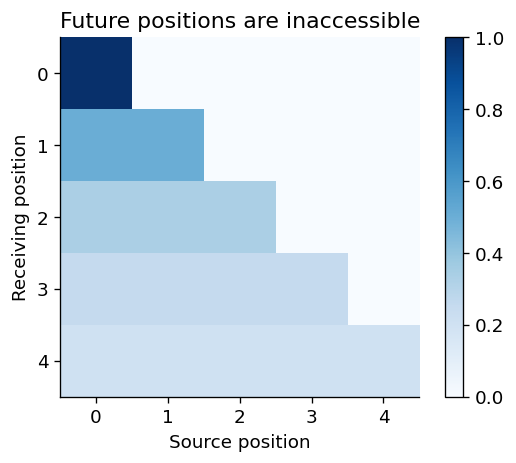

In [18]:
T=5
mask=np.where(np.triu(np.ones((T,T)),1)>0,-1e9,0.)
base_scores=np.zeros((T,T))
causal_A=softmax(base_scores+mask)
print('Uniform causal attention rows:',causal_A,sep='\n')
assert np.allclose(np.triu(causal_A,1),0)
fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(causal_A,cmap='Blues',vmin=0,vmax=1)
ax.set(xlabel='Source position',ylabel='Receiving position',title='Future positions are inaccessible')
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()


## 20. Positions, multiple heads, and positionwise MLPs

### 20.1 Why position information is necessary

Self-attention without positional information is permutation equivariant in its unmasked form: permuting the input rows permutes the output rows correspondingly. It has no intrinsic label for “first” or “third.” A causal mask introduces an order-dependent visibility pattern, but explicit position information remains important for representing distances and order in practical architectures.

Our model uses a learned position table $P\in\mathbb R^{T_{\max}\times d}$:

$$X_t=E_{\mathrm{token}_t}+P_t.$$

Token and position vectors must have the same width to add them. A learned table has no automatic guarantee of extrapolating beyond trained positions. Other schemes include sinusoidal encodings and rotary position embeddings. They change the representation of position; none is a universal solution to arbitrarily long reasoning.

For reference, sinusoidal positions use paired coordinates such as

$$P_{t,2i}=\sin\!\left(t/10000^{2i/d}\right),\qquad
P_{t,2i+1}=\cos\!\left(t/10000^{2i/d}\right).$$

The coordinate index is $i$ and position is $t$. Different frequencies provide position-dependent patterns. You need not memorize this formula to understand our learned-position capstone.

### 20.2 Multi-head attention

One head produces one content-dependent mixture. With $H$ heads, the model produces $H$ mixtures in different learned projection spaces, concatenates their outputs, and projects back:

$$\operatorname{MHA}(X)=\operatorname{Concat}(O^{(1)},\ldots,O^{(H)})W_O.$$

If model width $d=24$ and $H=2$, each head in our implementation has width $d_h=12$. Concatenating two 12-wide outputs restores width 24. Multiple heads make different routing patterns available; they are not guaranteed to specialize into tidy roles, and heads can be redundant.

### 20.3 The MLP inside each block

A transformer also applies an MLP separately at every position, sharing its parameters across positions:

$$\operatorname{MLP}(x)=\phi(xW_1+b_1)W_2+b_2.$$

Attention mixes information **across positions**. The positionwise MLP mixes and nonlinearly transforms **coordinates at a position**. Both are learned. Calling attention “reasoning” and the MLP “memory” is an oversimplification: useful facts and computations can be distributed across both.

Our capstone uses ReLU. Other activations, such as GELU and gated variants, are common architecture choices. Different activation choices change the function and its optimization, but the chain-rule learning story remains.


Combined: (2, 5, 24) Separated heads: (2, 2, 5, 12)


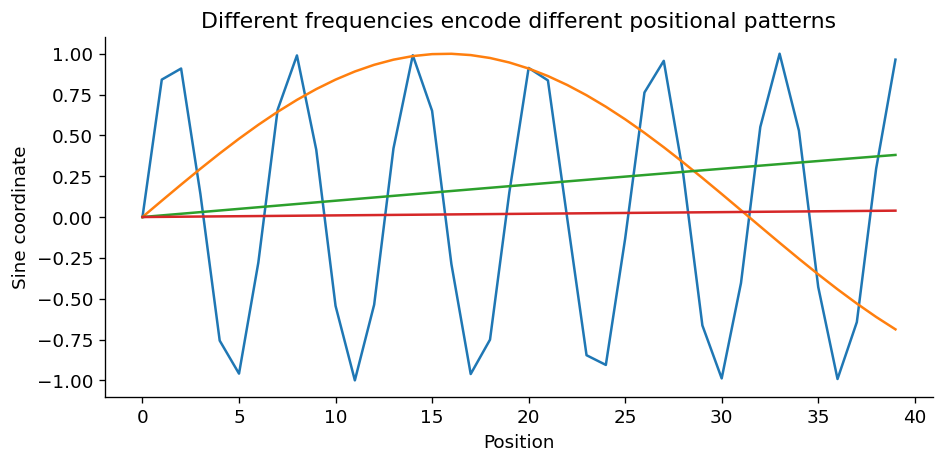

In [19]:
# See why reshape and transpose are different operations.
B,T,d,H=2,5,24,2
arr=np.arange(B*T*d).reshape(B,T,d)
heads=arr.reshape(B,T,H,d//H).transpose(0,2,1,3)
restored=heads.transpose(0,2,1,3).reshape(B,T,d)
print('Combined:',arr.shape,'Separated heads:',heads.shape)
assert np.array_equal(arr,restored)
# Positional patterns for a few sinusoidal coordinates.
pos=np.arange(40)[:,None]; dims=np.arange(0,8,2)[None,:]
angles=pos/(10000**(dims/8))
plt.plot(pos[:,0],np.sin(angles)); plt.xlabel('Position'); plt.ylabel('Sine coordinate')
plt.title('Different frequencies encode different positional patterns'); plt.tight_layout(); plt.show()


## 21. Residual connections and layer normalization

### 21.1 Residual connections

A residual update adds a transformation to its input:

$$y=x+F(x).$$

The shapes of $x$ and $F(x)$ must match. Its derivative includes an identity path:

$$\frac{\partial y}{\partial x}=I+\frac{\partial F}{\partial x}.$$

$I$ is the identity transformation. This direct path helps information and gradients propagate. It does not guarantee perfect optimization, and layers can still substantially alter representations.

The evolving sequence representation is often called the **residual stream**. Attention and MLP sublayers read from and write updates to this stream. This is a helpful computational view because many transformations share the same representational workspace.

### 21.2 Layer normalization, calculated on one vector

For a vector $x$ of width $d$, compute

$$\mu=\frac1d\sum_ix_i,\qquad v=\frac1d\sum_i(x_i-\mu)^2,$$
$$\operatorname{LN}(x)_i=\gamma_i\frac{x_i-\mu}{\sqrt{v+\epsilon}}+\beta_i.$$

$\gamma$ and $\beta$ are learned scale and shift parameters. $\epsilon>0$ stabilizes division. This normalizes each token's coordinates independently; it is not normalization across all examples in a batch.

For $x=[1,2,3]$, $\mu=2$ and $v=(1+0+1)/3=2/3$. Ignoring the tiny $\epsilon$ and setting $\gamma=1,\beta=0$, the normalized result is approximately $[-1.2247,0,1.2247]$. Normalization controls scale; it does not assign semantic meaning to coordinates.

### 21.3 One complete pre-normalization block

Our decoder block uses

$$U=X+\operatorname{MHA}(\operatorname{LN}_1(X)),$$
$$Y=U+\operatorname{MLP}(\operatorname{LN}_2(U)).$$

**Pre-normalization** means normalizing before each sublayer. Other architectures place normalization elsewhere or use variants such as RMS normalization. Those are architectural differences, not evidence for a different kind of intelligence.

Stacking these blocks allows later operations to use features computed earlier. This matters for multistep computations: a second relation can be evaluated using a first relation's result rather than only raw tokens.


In [20]:
x=np.array([1.,2.,3.])
norm=(x-x.mean())/np.sqrt(x.var()+1e-5)
print('Mean:',x.mean(),'variance:',x.var(),'normalized:',norm)
print('Normalized mean:',norm.mean(),'normalized variance:',norm.var())


Mean: 2.0 variance: 0.6666666666666666 normalized: [-1.2247  0.      1.2247]
Normalized mean: 0.0 normalized variance: 0.9999850002249967


## 22. From a residual stream to vocabulary probabilities

After $L$ decoder blocks, the model has a representation $h_t\in\mathbb R^d$ at each position. An output projection, often called the **unembedding**, produces $V$ logits:

$$z_t=h_tW_U+b_U,\qquad p_t=\operatorname{softmax}(z_t).$$

$W_U$ has shape $(d,V)$. Some models tie it to the transpose of the input embedding matrix; ours does not. Each logit is a learned linear readout of the final representation. The final softmax converts logits to the next-token distribution.

For a target sequence, the mean next-token loss is

$$\mathcal L=-\frac1N\sum_{n=1}^N\log p_\theta(t_n\mid t_{<n}),$$

where $N$ counts supervised, non-padding positions across examples. Negative log-likelihood of a whole sequence sums these terms; averaging changes scale, not which fixed dataset solution minimizes the objective. **Perplexity** is $e^{\mathcal L}$ when natural-log loss is averaged per token. Comparisons require comparable tokenization and evaluation data.

### Decoding is a policy applied to the distribution

**Greedy decoding** picks the largest probability at each step. **Sampling** draws a random token. **Temperature** $\tau>0$ changes the distribution to $\operatorname{softmax}(z/\tau)$: lower values concentrate it, higher values flatten it. Temperature does not add knowledge or ensure validity. Top-$k$ sampling restricts choices to the $k$ largest logits before renormalization. Changing decoding changes outputs without changing the trained weights.

Greedy locally best choices do not necessarily produce the most probable complete sequence, much less the most correct solution. Sequence probability and task correctness are different objectives.

### Parameters versus temporary state

Weights persist across requests. Activations depend on this request. The **KV cache** stores earlier keys and values per layer to avoid recomputing them during generation. It is temporary inference state, not ordinary gradient-based learning. A new generated token can attend to cached prior information, but appending a token does not automatically update old positions' representations.

For conventional dense attention, constructing a $T\times T$ attention matrix costs quadratic space in sequence length in a straightforward implementation. Approximate block computation costs include $O(Td^2)$ for projections/MLPs and $O(T^2d)$ for attention. Efficient kernels may avoid materializing the full matrix; they do not make every sequence-length cost disappear.

**Transition:** all the ingredients of a decoder transformer are now defined. We will assemble and train one before discussing reasoning in large models, so the later explanations have a concrete numerical anchor.


In [21]:
z=np.array([2.,1.,0.])
for tau in [.3,1.,2.]: print('Temperature',tau,'probabilities',softmax(z/tau))
# Approximate bytes in an ordinary float32 KV cache, ignoring overhead:
# two tensors (K and V), layers, batch, positions, heads, head width.
L,B,T,H,dh=12,1,2048,12,64
cache_bytes=2*L*B*T*H*dh*4
print('Illustrative KV cache MiB:',round(cache_bytes/2**20,2))


Temperature 0.3 probabilities [0.9644 0.0344 0.0012]
Temperature 1.0 probabilities [0.6652 0.2447 0.09  ]
Temperature 2.0 probabilities [0.5065 0.3072 0.1863]
Illustrative KV cache MiB: 144.0


### A visual map of the complete computation

Read the following drawing from bottom to top. The model transforms a sequence of input IDs into a distribution at each position. The same learned block parameters are reused over positions, but each block has its own parameter values. During training, target tokens supply a loss; gradients flow backward through the operations. During generation, the selected new token is appended and another forward pass begins.

The drawing omits many individual arrays so the main dependencies stay visible. The equations and capstone code specify the operations precisely. In particular, “attention” includes learned projections, causal scores, softmax, weighted values, and an output projection.


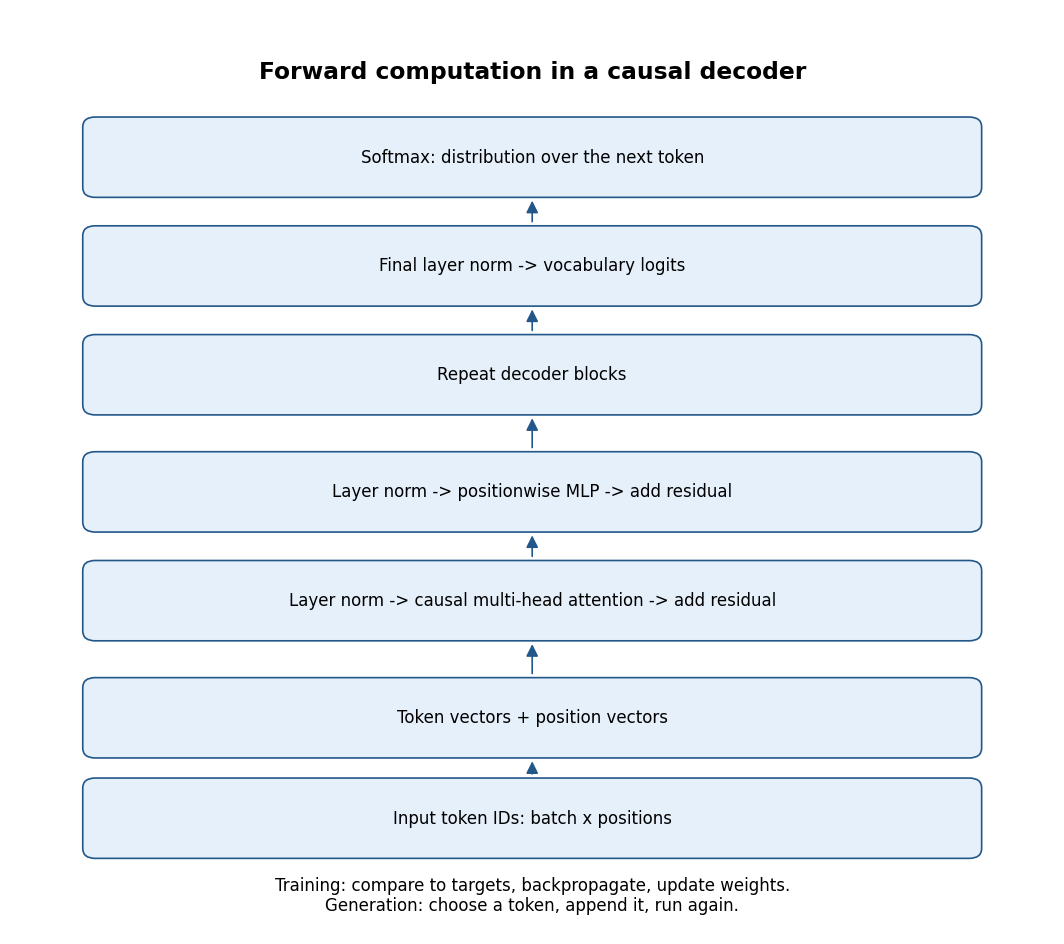

In [22]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig,ax=plt.subplots(figsize=(9,8))
ax.set(xlim=(0,10),ylim=(0,11)); ax.axis('off')
boxes=[(1.0,'Input token IDs: batch x positions'),
       (2.2,'Token vectors + position vectors'),
       (3.6,'Layer norm -> causal multi-head attention -> add residual'),
       (4.9,'Layer norm -> positionwise MLP -> add residual'),
       (6.3,'Repeat decoder blocks'),
       (7.6,'Final layer norm -> vocabulary logits'),
       (8.9,'Softmax: distribution over the next token')]
for y,label in boxes:
    ax.add_patch(FancyBboxPatch((.8,y),8.4,.72,boxstyle='round,pad=.12',
                               facecolor='#e6f0fa',edgecolor='#235789'))
    ax.text(5,y+.36,label,ha='center',va='center',fontsize=10)
for (y,_),(ny,_) in zip(boxes[:-1],boxes[1:]):
    ax.add_patch(FancyArrowPatch((5,y+.85),(5,ny-.12),arrowstyle='-|>',mutation_scale=15,color='#235789'))
ax.text(5,10.2,'Forward computation in a causal decoder',ha='center',weight='bold',fontsize=14)
ax.text(5,.25,'Training: compare to targets, backpropagate, update weights.\nGeneration: choose a token, append it, run again.',ha='center',fontsize=10)
plt.tight_layout(); plt.show()


# Part IV — Build and interrogate a complete small transformer
## 23. Automatic differentiation without a deep-learning framework

We could install a framework and call `loss.backward()`. Instead, we will implement the small subset needed for this model, so that “backward” has a visible meaning.

A **computational graph** records how values were created. A graph node stores its numerical array, its accumulated gradient, and a local backward rule. To differentiate a scalar loss:

1. Visit its ancestors in dependency order.
2. Clear gradients for this new computation.
3. Seed the loss's own gradient with 1: $\partial L/\partial L=1$.
4. Traverse the nodes in reverse order, adding each node's contributions to its parents.

This is reverse-mode automatic differentiation. It calculates chain-rule derivatives of the executed operations, up to numerical precision and nondifferentiable-point conventions. It is not finite-difference estimation and not symbolic simplification of a formula.

### Broadcasting must be reversed correctly

Suppose $Y=X+b$, with $X$ shaped $(B,d)$ and $b$ shaped $(d,)$. Each $b_j$ contributes to all $B$ rows. Its gradient is therefore the sum of the corresponding output gradients. Our `unbroadcast` helper sums introduced axes and axes that originally had size 1.

### Why indexing needs scatter-add

If an embedding row is selected at several positions, all those uses contribute to its gradient. Assigning a gradient into the row would overwrite earlier contributions. `np.add.at` accumulates them, including repeated indices.

### Boundaries of this teaching engine

It supports floating-point tensors, addition, multiplication, scalar powers, matrix multiplication with at least two axes, sums, reshape, transpose, indexing, exponential, logarithm, and ReLU. It has no GPU support, no sparse tensors, no mixed precision, and no higher-order derivatives. We test the operations we actually use. These explicit limits are preferable to silently implying that a hundred lines replace a production framework.


In [23]:
def unbroadcast(g, shape):
    while g.ndim > len(shape): g=g.sum(axis=0)
    for axis,size in enumerate(shape):
        if size==1 and g.shape[axis]!=1: g=g.sum(axis=axis,keepdims=True)
    return g.reshape(shape)

class Tensor:
    def __init__(self, data, requires_grad=False, parents=()):
        self.data=np.asarray(data,dtype=np.float64)
        self.requires_grad=requires_grad
        self.grad=None
        self.parents=parents
        self._backward=lambda: None
    @property
    def shape(self): return self.data.shape
    def add_grad(self,g):
        if self.requires_grad:
            self.grad=g.copy() if self.grad is None else self.grad+g
    def __add__(self,other):
        other=as_tensor(other)
        out=Tensor(self.data+other.data,self.requires_grad or other.requires_grad,(self,other))
        def back():
            self.add_grad(unbroadcast(out.grad,self.shape))
            other.add_grad(unbroadcast(out.grad,other.shape))
        out._backward=back
        return out
    __radd__=__add__
    def __neg__(self): return self*(-1)
    def __sub__(self,other): return self+(-as_tensor(other))
    def __rsub__(self,other): return as_tensor(other)+(-self)
    def __mul__(self,other):
        other=as_tensor(other)
        out=Tensor(self.data*other.data,self.requires_grad or other.requires_grad,(self,other))
        def back():
            self.add_grad(unbroadcast(out.grad*other.data,self.shape))
            other.add_grad(unbroadcast(out.grad*self.data,other.shape))
        out._backward=back
        return out
    __rmul__=__mul__
    def __pow__(self,power):
        out=Tensor(self.data**power,self.requires_grad,(self,))
        out._backward=lambda: self.add_grad(out.grad*power*self.data**(power-1))
        return out
    def __truediv__(self,other): return self*(as_tensor(other)**-1)
    def __matmul__(self,other):
        other=as_tensor(other)
        assert self.data.ndim>=2 and other.data.ndim>=2
        out=Tensor(self.data@other.data,self.requires_grad or other.requires_grad,(self,other))
        def back():
            self.add_grad(unbroadcast(out.grad@np.swapaxes(other.data,-1,-2),self.shape))
            other.add_grad(unbroadcast(np.swapaxes(self.data,-1,-2)@out.grad,other.shape))
        out._backward=back
        return out
    def sum(self,axis=None,keepdims=False):
        out=Tensor(self.data.sum(axis=axis,keepdims=keepdims),self.requires_grad,(self,))
        def back():
            g=out.grad
            if axis is not None and not keepdims:
                axes=(axis,) if isinstance(axis,int) else axis
                for a in sorted(a % self.data.ndim for a in axes): g=np.expand_dims(g,a)
            self.add_grad(np.broadcast_to(g,self.shape))
        out._backward=back
        return out
    def mean(self,axis=None,keepdims=False):
        if axis is None: n=self.data.size
        else:
            axes=(axis,) if isinstance(axis,int) else axis
            n=math.prod(self.shape[a] for a in axes)
        return self.sum(axis=axis,keepdims=keepdims)/n
    def reshape(self,*shape):
        out=Tensor(self.data.reshape(*shape),self.requires_grad,(self,))
        out._backward=lambda: self.add_grad(out.grad.reshape(self.shape))
        return out
    def transpose(self,*axes):
        if not axes: axes=tuple(reversed(range(self.data.ndim)))
        out=Tensor(self.data.transpose(axes),self.requires_grad,(self,))
        inverse=tuple(np.argsort(axes))
        out._backward=lambda: self.add_grad(out.grad.transpose(inverse))
        return out
    def __getitem__(self,index):
        out=Tensor(self.data[index],self.requires_grad,(self,))
        def back():
            if self.requires_grad:
                g=np.zeros_like(self.data); np.add.at(g,index,out.grad); self.add_grad(g)
        out._backward=back
        return out
    def exp(self):
        out=Tensor(np.exp(self.data),self.requires_grad,(self,))
        out._backward=lambda: self.add_grad(out.grad*out.data)
        return out
    def log(self):
        out=Tensor(np.log(self.data),self.requires_grad,(self,))
        out._backward=lambda: self.add_grad(out.grad/self.data)
        return out
    def relu(self):
        out=Tensor(np.maximum(self.data,0),self.requires_grad,(self,))
        out._backward=lambda: self.add_grad(out.grad*(self.data>0))
        return out
    def backward(self):
        assert self.data.size==1, 'Seed a scalar objective.'
        ordered=[]; visited=set()
        def visit(node):
            if id(node) in visited: return
            visited.add(id(node))
            for parent in node.parents: visit(parent)
            ordered.append(node)
        visit(self)
        for node in ordered: node.grad=None
        self.grad=np.ones_like(self.data)
        for node in reversed(ordered):
            if node.grad is not None: node._backward()

def as_tensor(x): return x if isinstance(x,Tensor) else Tensor(x)
def tensor_softmax(x,axis=-1):
    # The subtracted maximum is treated as a constant. Softmax is invariant
    # to a common shift, so this preserves the correct softmax derivative.
    shifted=x-Tensor(x.data.max(axis=axis,keepdims=True))
    e=shifted.exp()
    return e/e.sum(axis=axis,keepdims=True)

def tensor_ce(logits,targets):
    # Stable cross-entropy for shape (batch, classes), averaged over examples.
    shift=logits-Tensor(logits.data.max(axis=-1,keepdims=True))
    log_normalizer=shift.exp().sum(axis=-1).log()
    correct=shift[np.arange(len(targets)),targets]
    return (log_normalizer-correct).mean()


### 23.1 Check gradients before trusting training

A decreasing loss is useful but insufficient evidence of a correct implementation. A wrong gradient can still happen to reduce loss. We compare autodiff derivatives to **central finite differences**:

$$g_i^{\rm numeric}=\frac{L(\theta+\epsilon e_i)-L(\theta-\epsilon e_i)}{2\epsilon}.$$

$e_i$ is a vector with 1 at coordinate $i$ and zeros elsewhere. We perturb one coordinate while holding the rest fixed. Central differences have approximation error for finite $\epsilon$ and rounding error if $\epsilon$ is too tiny. Values near ReLU's kink can disagree because the derivative there is undefined; use smooth test points or explain the kink.

Our tests exercise shared parameters, repeated embedding indices, broadcasting, batched matrix multiplication, transpose/reshape, and the normalization formula. Later we also check selected parameters of the assembled transformer.


In [24]:
# A reused scalar: d(x*x+x)/dx at x=3 must be 7.
tx=Tensor(3.,True); tloss=tx*tx+tx; tloss.backward()
assert np.allclose(tx.grad,7.)
# Repeated indexing must add, not overwrite.
table=Tensor(np.arange(6.).reshape(3,2),True)
table[np.array([1,1,2])].sum().backward()
assert np.allclose(table.grad,[[0,0],[2,2],[1,1]])

rng=np.random.default_rng(21)
ta=Tensor(rng.normal(size=(2,3,4)),True)
tb=Tensor(rng.normal(size=(4,5)),True)
t_bias=Tensor(rng.normal(size=(5,)),True)
def test_objective():
    z=(ta@tb+t_bias).transpose(0,2,1).reshape(2,15)
    p=tensor_softmax(z)
    return (p*Tensor(np.arange(15)[None,:])).sum()
test_objective().backward()
errors=[]
for param,idx in [(ta,(1,2,3)),(tb,(2,1)),(t_bias,(3,))]:
    expected=param.grad[idx]; original=param.data[idx]; e=1e-5
    param.data[idx]=original+e; plus=test_objective().data.item()
    param.data[idx]=original-e; minus=test_objective().data.item()
    param.data[idx]=original
    errors.append(abs(expected-(plus-minus)/(2*e)))
print('Autodiff finite-difference absolute errors:',errors)
assert max(errors)<1e-6
print('Scalar reuse, repeated indexing, batched matmul, broadcasting and softmax checks passed.')


Autodiff finite-difference absolute errors: [np.float64(1.382104018905761e-10), np.float64(7.570832849523867e-11), np.float64(2.1846979780804077e-10)]
Scalar reuse, repeated indexing, batched matmul, broadcasting and softmax checks passed.


## 24. A full decoder transformer, line by line

Our model receives seven tokens:

`<bos> K_a V_b K_c V_d <query> K_a`

and must predict `V_b`. `<bos>` marks the beginning. `K_a` is a key token; `V_b` is a value token. Each prompt defines **new local facts**. The association between a particular key and value varies between prompts, so a single permanent key-to-value dictionary will not solve the task.

This is **associative recall**. It requires selecting the pair named by the final query. It is useful as a small example of context-dependent computation. It is not a demonstration of general language competence, deductive theorem proving, or humanlike reasoning.

### Architecture and shape ledger

| Stage | Shape | Meaning |
|---|---|---|
| Integer input | $(B,T)$ | Token IDs, $T=7$ |
| Token plus position lookup | $(B,T,d)$ | Initial residual stream |
| Projected Q/K/V | $(B,T,d)$ | Combined heads |
| Reshaped Q/K/V | $(B,H,T,d_h)$ | Separate heads |
| Scores / attention | $(B,H,T,T)$ | Receiver-by-source routing |
| Head outputs | $(B,H,T,d_h)$ | Mixed values |
| Combined attention output | $(B,T,d)$ | Projected residual update |
| Positionwise MLP | $(B,T,d_{ff})\to(B,T,d)$ | Nonlinear feature update |
| Final vocabulary logits | $(B,T,V)$ | Scores for every next token |

We train the loss only at the final prompt position. This is supervised answer prediction using a causal decoder, not full next-token pretraining on every prompt position. It uses the same kind of last-position distribution that autoregressive generation would use for its next token, but the training task and supervision are deliberately narrower.

### Read the block in computation order

`layer_norm` standardizes each token's coordinates. `q`, `k`, and `v` are linear projections. `reshape` exposes heads; `transpose` places them before the position axis so matrix multiplication applies independently per head. The mask removes future access. The weighted values are recombined and added to the residual stream. A second normalization and MLP add another update. Two blocks compose these operations.

The model can express a useful pattern such as making earlier positions represent adjacent key–value relationships, then letting the final query retrieve a matching value. **That is a possible mechanism, not an established description of the exact model we will train.** Its actual solution may be distributed or use shortcuts. The ablations below provide limited evidence, not a complete circuit analysis.


In [25]:
class TinyDecoder:
    def __init__(self,vocab_size,max_len=7,d=24,heads=2,layers=2,ff=48,seed=31):
        assert d%heads==0
        self.rng=np.random.default_rng(seed)
        self.d=d; self.heads=heads; self.dh=d//heads; self.max_len=max_len
        self.params=[]; self.named={}; self.blocks=[]
        def parameter(name,shape,scale=None,fill=None):
            if fill is None:
                s=(1/np.sqrt(shape[0])) if scale is None else scale
                data=self.rng.normal(0,s,shape)
            else: data=np.full(shape,fill,dtype=float)
            p=Tensor(data,True); self.params.append(p); self.named[name]=p; return p
        self.E=parameter('embedding',(vocab_size,d),scale=.15)
        self.P=parameter('position',(max_len,d),scale=.08)
        for layer in range(layers):
            b={}
            for name in ['g1','g2']: b[name]=parameter(f'{layer}.{name}',(d,),fill=1.)
            for name in ['b1','b2']: b[name]=parameter(f'{layer}.{name}',(d,),fill=0.)
            for name in ['Q','K','V','O']: b[name]=parameter(f'{layer}.{name}',(d,d))
            b['F1']=parameter(f'{layer}.F1',(d,ff))
            b['fb1']=parameter(f'{layer}.fb1',(ff,),fill=0.)
            b['F2']=parameter(f'{layer}.F2',(ff,d))
            b['fb2']=parameter(f'{layer}.fb2',(d,),fill=0.)
            self.blocks.append(b)
        self.fg=parameter('final_gain',(d,),fill=1.)
        self.fb=parameter('final_bias',(d,),fill=0.)
        self.U=parameter('unembedding',(d,vocab_size))
        self.ub=parameter('output_bias',(vocab_size,),fill=0.)
    def layer_norm(self,x,gain,bias):
        center=x-x.mean(axis=-1,keepdims=True)
        variance=(center*center).mean(axis=-1,keepdims=True)
        return center*(variance+1e-5)**-.5*gain+bias
    def forward(self,ids,uniform_attention=False,return_attention=False):
        B,T=ids.shape
        assert T<=self.max_len
        x=self.E[ids]+self.P[np.arange(T)]
        mask=Tensor(np.where(np.triu(np.ones((T,T)),1)>0,-1e9,0.))
        saved=[]
        for block in self.blocks:
            n=self.layer_norm(x,block['g1'],block['b1'])
            q=(n@block['Q']).reshape(B,T,self.heads,self.dh).transpose(0,2,1,3)
            k=(n@block['K']).reshape(B,T,self.heads,self.dh).transpose(0,2,1,3)
            v=(n@block['V']).reshape(B,T,self.heads,self.dh).transpose(0,2,1,3)
            scores=(q@k.transpose(0,1,3,2))*(self.dh**-.5)+mask
            if uniform_attention:
                weights=Tensor(softmax(np.broadcast_to(mask.data,(B,self.heads,T,T))))
            else: weights=tensor_softmax(scores)
            saved.append(weights.data.copy())
            combined=(weights@v).transpose(0,2,1,3).reshape(B,T,self.d)
            x=x+combined@block['O']
            n=self.layer_norm(x,block['g2'],block['b2'])
            x=x+(n@block['F1']+block['fb1']).relu()@block['F2']+block['fb2']
        logits=self.layer_norm(x,self.fg,self.fb)@self.U+self.ub
        return (logits,saved) if return_attention else logits

tokens=['<bos>','<query>']+[f'K{i}' for i in range(5)]+[f'V{i}' for i in range(5)]
token_to_id={t:i for i,t in enumerate(tokens)}
model=TinyDecoder(len(tokens))
print('Vocabulary:',tokens)
print('Trainable numbers:',sum(p.data.size for p in model.params))
print('Layers:',len(model.blocks),'heads:',model.heads,'width:',model.d)


Vocabulary: ['<bos>', '<query>', 'K0', 'K1', 'K2', 'K3', 'K4', 'V0', 'V1', 'V2', 'V3', 'V4']
Trainable numbers: 10356
Layers: 2 heads: 2 width: 24


### 24.1 Data splitting: hold out whole local mappings

We use five possible key symbols and five value symbols. Each prompt contains two **distinct** keys mapped to two **distinct** values. For an unordered key pair there are $\binom52=10$ choices; assigning distinct values to the two canonical keys gives $5\times4=20$ choices. There are therefore 200 mapping groups.

For each group, we create four prompt variants: two orders of the pairs, times two possible queries. We split at the **mapping-group** level before expanding variants. This prevents the same local mapping from appearing in training in one order and testing in another.

Training contains 160 groups and held-out evaluation 40 groups. Individual keys and values appear in both sets; the held-out object is the joint two-pair assignment. This tests a limited form of recombination. It does not withhold every individual key–value association, test unseen symbols, or test longer contexts.

We use this held-out set as a diagnostic within a teaching experiment. Once we inspect it and decide on changes, it is effectively validation data. A publication-quality final estimate would need another untouched test split and multiple seeds.

The data contain structure that models can exploit: fixed length, alternating key/value positions, distinct values, and only two pairs. We will discuss those shortcuts when interpreting results.


In [26]:
groups=[]
for ka,kb in itertools.combinations(range(5),2):
    for va,vb in itertools.permutations(range(5),2):
        groups.append(((ka,va),(kb,vb)))
rng=np.random.default_rng(123)
order=rng.permutation(len(groups))
train_group_ids=set(order[:160].tolist()); heldout_group_ids=set(order[160:].tolist())
assert train_group_ids.isdisjoint(heldout_group_ids)

def expand_groups(group_ids):
    xs=[]; ys=[]
    for gid in sorted(group_ids):
        pair1,pair2=groups[gid]
        for pairs in [(pair1,pair2),(pair2,pair1)]:
            for query_key,answer_value in [pair1,pair2]:
                prompt=['<bos>']
                for key,value in pairs: prompt += [f'K{key}',f'V{value}']
                prompt += ['<query>',f'K{query_key}']
                xs.append([token_to_id[t] for t in prompt])
                ys.append(token_to_id[f'V{answer_value}'])
    return np.array(xs,dtype=int),np.array(ys,dtype=int)
train_ids,train_targets=expand_groups(train_group_ids)
heldout_ids,heldout_targets=expand_groups(heldout_group_ids)
print('Training prompts:',train_ids.shape,'held-out prompts:',heldout_ids.shape)
print('Example:',[tokens[i] for i in train_ids[0]],'->',tokens[train_targets[0]])
print('Uniform-vocabulary chance:',1/len(tokens))
print('Uniform-value chance:',1/5,'Choosing randomly between the two present values:',.5)


Training prompts: (640, 7) held-out prompts: (160, 7)
Example: ['<bos>', 'K0', 'V0', 'K1', 'V1', '<query>', 'K0'] -> V0
Uniform-vocabulary chance: 0.08333333333333333
Uniform-value chance: 0.2 Choosing randomly between the two present values: 0.5


### 24.2 Check the assembled model and causal mask

There are two different checks here. A **gradient check** compares selected parameter derivatives to finite differences. A **causality check** changes future input tokens and verifies that earlier-position logits stay identical. The latter catches a mask or transpose bug even if optimization appears to work.

The finite-difference check includes an embedding coordinate, a query projection coordinate, and a normalization gain. It does not exhaustively verify every parameter, but it exercises the full path from those parameters to the final loss. The primitive-operation checks give additional coverage.


In [27]:
small_ids=train_ids[:3]; small_targets=train_targets[:3]
loss=tensor_ce(model.forward(small_ids)[:,-1,:],small_targets)
loss.backward()
checks=[]
for name,idx in [('embedding',(2,3)),('0.Q',(1,2)),('0.g1',(4,))]:
    p=model.named[name]; analytic=float(p.grad[idx]); old=float(p.data[idx]); e=1e-5
    p.data[idx]=old+e; lp=tensor_ce(model.forward(small_ids)[:,-1,:],small_targets).data.item()
    p.data[idx]=old-e; lm=tensor_ce(model.forward(small_ids)[:,-1,:],small_targets).data.item()
    p.data[idx]=old
    numeric=(lp-lm)/(2*e)
    checks.append(abs(analytic-numeric))
    print(name,'analytic:',round(analytic,8),'numeric:',round(numeric,8))
assert max(checks)<1e-5
original=train_ids[:2].copy(); changed=original.copy()
changed[:,4:]=np.roll(changed[:,4:],1,axis=1)
a=model.forward(original).data[:,:4,:]
b=model.forward(changed).data[:,:4,:]
print('Largest earlier-logit change after changing future:',np.max(np.abs(a-b)))
assert np.allclose(a,b,atol=1e-10)


embedding analytic: -1.71058489 numeric: -1.71058489
0.Q analytic: -0.02683618 numeric: -0.02683618
0.g1 analytic: -0.16811931 numeric: -0.16811931
Largest earlier-logit change after changing future: 0.0


### 24.3 Train using Adam and gradient clipping

The optimizer maintains first and second moments for each parameter. We clip the **global gradient norm**, the square root of the sum of squared entries across all parameter gradients. If the norm exceeds 1, multiply all gradients by $1/\|g\|$ before applying Adam. We retain relative directions while limiting magnitude.

The model is trained from random weights. The final-position loss must learn which present value is associated with the queried key. It is not given a separate instruction saying “implement a two-hop circuit.”

This loop performs a fixed number of updates and prints occasional diagnostics. No expensive model or dataset is downloaded. NumPy and your BLAS implementation determine the exact speed. Set `TRAIN_STEPS` lower for a quick smoke test; results after fewer steps may be much weaker. For the saved notebook we use the default setting shown below.


Update    1: minibatch loss 3.0421; held-out loss 2.3284; accuracy 3.1%
Update  200: minibatch loss 0.8201; held-out loss 0.8875; accuracy 44.4%
Update  400: minibatch loss 0.5973; held-out loss 0.6870; accuracy 63.1%
Update  600: minibatch loss 0.1690; held-out loss 0.2490; accuracy 95.0%
Update  800: minibatch loss 0.0049; held-out loss 0.0463; accuracy 98.8%
Update 1000: minibatch loss 0.0018; held-out loss 0.0303; accuracy 99.4%
Update 1200: minibatch loss 0.0005; held-out loss 0.0576; accuracy 98.1%
Update 1400: minibatch loss 0.0006; held-out loss 0.0124; accuracy 99.4%
Training seconds: 26.17
Final train loss/accuracy: (0.0008629494021298919, 1.0)
Final held-out loss/accuracy: (0.012375896009264534, 0.99375)


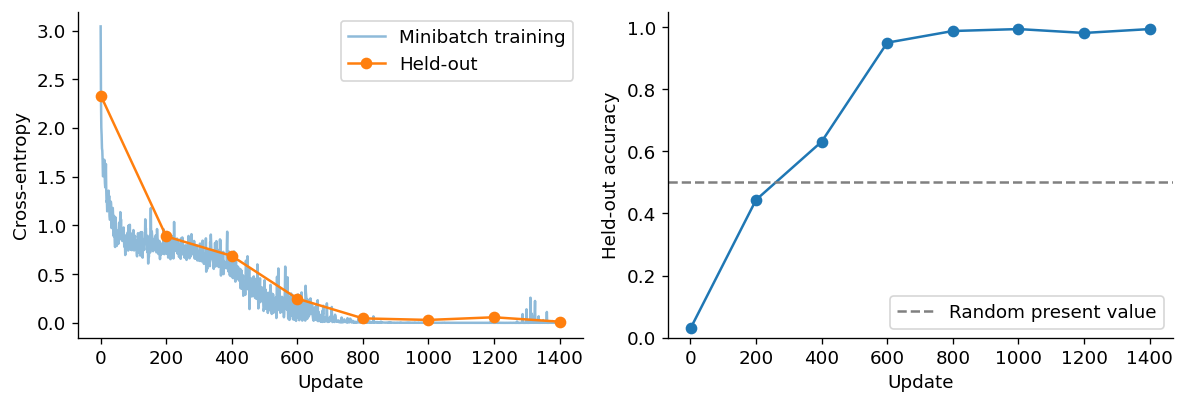

In [28]:
TRAIN_STEPS=1400
BATCH_SIZE=32
rng=np.random.default_rng(321)
moments=[np.zeros_like(p.data) for p in model.params]
second=[np.zeros_like(p.data) for p in model.params]
train_curve=[]; eval_curve=[]

def evaluate(ids,targets,uniform_attention=False):
    logits=model.forward(ids,uniform_attention=uniform_attention).data[:,-1,:]
    probabilities=softmax(logits)
    return float(-np.log(probabilities[np.arange(len(targets)),targets]+1e-30).mean()), float((logits.argmax(-1)==targets).mean())

started=time.perf_counter()
for step in range(1,TRAIN_STEPS+1):
    selection=rng.integers(0,len(train_ids),size=BATCH_SIZE)
    loss=tensor_ce(model.forward(train_ids[selection])[:,-1,:],train_targets[selection])
    loss.backward()
    grad_norm=np.sqrt(sum(np.sum(p.grad**2) for p in model.params))
    clip=min(1.,1./(grad_norm+1e-12))
    for i,p in enumerate(model.params):
        g=p.grad*clip
        moments[i]=.9*moments[i]+.1*g
        second[i]=.999*second[i]+.001*g*g
        mhat=moments[i]/(1-.9**step); vhat=second[i]/(1-.999**step)
        p.data-=.003*mhat/(np.sqrt(vhat)+1e-8)
    train_curve.append(loss.data.item())
    if step==1 or step%200==0:
        vl,va=evaluate(heldout_ids,heldout_targets)
        eval_curve.append((step,vl,va))
        print(f'Update {step:4d}: minibatch loss {loss.data.item():.4f}; held-out loss {vl:.4f}; accuracy {va:.1%}')
print('Training seconds:',round(time.perf_counter()-started,2))
print('Final train loss/accuracy:',evaluate(train_ids,train_targets))
print('Final held-out loss/accuracy:',evaluate(heldout_ids,heldout_targets))
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].plot(train_curve,alpha=.5,label='Minibatch training')
axs[0].plot([v[0] for v in eval_curve],[v[1] for v in eval_curve],marker='o',label='Held-out')
axs[0].set(xlabel='Update',ylabel='Cross-entropy'); axs[0].legend()
axs[1].plot([v[0] for v in eval_curve],[v[2] for v in eval_curve],marker='o')
axs[1].axhline(.5,color='gray',ls='--',label='Random present value')
axs[1].set(xlabel='Update',ylabel='Held-out accuracy',ylim=(0,1.05)); axs[1].legend()
plt.tight_layout(); plt.show()


## 25. Interrogate the trained computation instead of admiring the curve

### 25.1 Read individual predictions

A high average accuracy can hide systematic failures. We display probabilities assigned to the correct value and the predicted token for individual held-out prompts. These probabilities are normalized scores under our model; they are not certified correctness probabilities for arbitrary future tasks.

### 25.2 Change facts and ask whether answers follow

A **counterfactual input intervention** changes the prompt while preserving the rule. Swapping the two values should swap the answer for the same queried key. This helps test whether the output follows the local association rather than a permanent key-to-value mapping.

### 25.3 Replace learned attention weights with uniform causal weights

This intervention preserves value projections, MLPs, positions, and the causal visibility pattern, while replacing input-dependent routing with uniform averaging over permitted positions. A performance drop suggests the trained routing matters **for this trained parameter setting**. It does not prove that no model trained from scratch with uniform mixing could solve the task. Intervening on a trained model and comparing architecture families after retraining are different experiments.

### 25.4 Look at attention without treating it as an explanation

An attention heatmap shows where one head routes information. It does not show all value content, output projection effects, MLP computations, or residual paths. A high weight is not proof of a causal or semantically meaningful reasoning step. Causal interventions and circuit analysis provide stronger evidence, and can themselves have artifacts when activations are pushed off their normal distribution.


<bos> K0 V1 K1 V2 <query> K0 => V1 | target V1 | P(target) 1.0
<bos> K0 V1 K1 V2 <query> K1 => V2 | target V2 | P(target) 1.0
<bos> K1 V2 K0 V1 <query> K0 => V1 | target V1 | P(target) 1.0
<bos> K1 V2 K0 V1 <query> K1 => V2 | target V2 | P(target) 1.0
<bos> K0 V1 K1 V3 <query> K0 => V1 | target V1 | P(target) 1.0
<bos> K0 V1 K1 V3 <query> K1 => V3 | target V3 | P(target) 1.0
Swapped-value accuracy: 1.0
Normal held-out loss/accuracy: (0.012375896009264534, 0.99375)
Uniform-attention intervention loss/accuracy: (2.098061717933736, 0.48125)


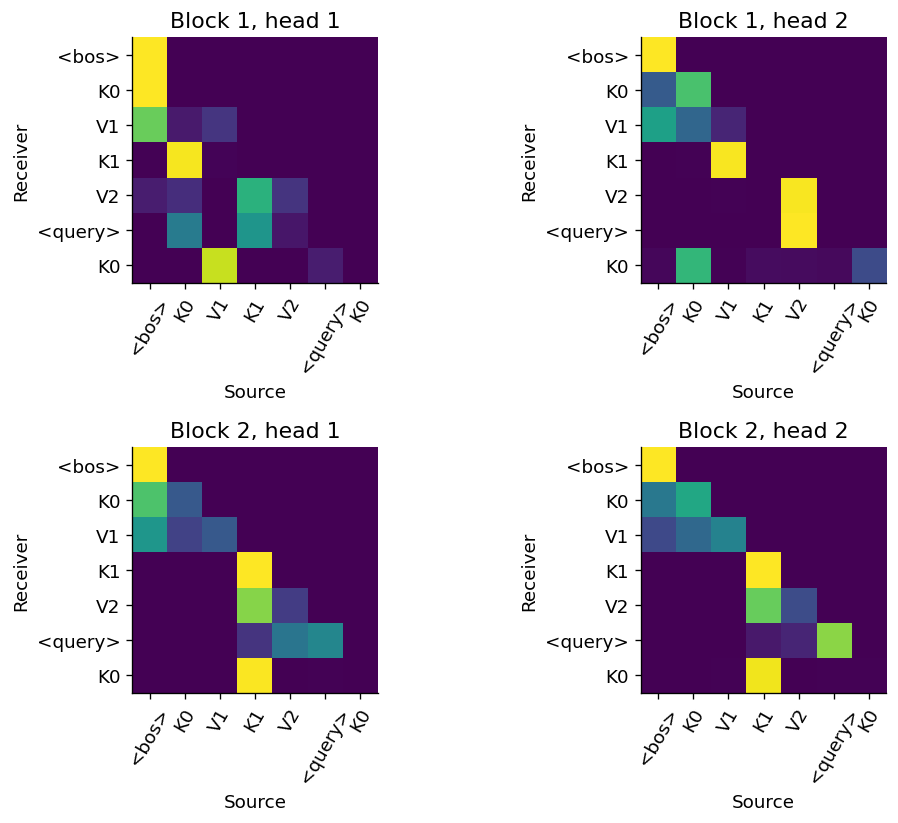

In [29]:
held_logits,attention_maps=model.forward(heldout_ids[:6],return_attention=True)
held_p=softmax(held_logits.data[:,-1,:])
for i in range(6):
    prompt=' '.join(tokens[t] for t in heldout_ids[i])
    print(prompt,'=>',tokens[held_p[i].argmax()],
          '| target',tokens[heldout_targets[i]],'| P(target)',round(held_p[i,heldout_targets[i]],3))

counter=heldout_ids.copy(); counter[:,[2,4]]=counter[:,[4,2]]
counter_targets=np.where(heldout_targets==heldout_ids[:,2],heldout_ids[:,4],heldout_ids[:,2])
print('Swapped-value accuracy:',evaluate(counter,counter_targets)[1])
print('Normal held-out loss/accuracy:',evaluate(heldout_ids,heldout_targets))
print('Uniform-attention intervention loss/accuracy:',evaluate(heldout_ids,heldout_targets,True))

fig,axs=plt.subplots(len(model.blocks),model.heads,figsize=(9,7),squeeze=False)
labels=[tokens[t] for t in heldout_ids[0]]
for layer,maps in enumerate(attention_maps):
    for head in range(model.heads):
        ax=axs[layer,head]; ax.imshow(maps[0,head],vmin=0,vmax=1,cmap='viridis')
        ax.set_xticks(range(7),labels,rotation=60); ax.set_yticks(range(7),labels)
        ax.set_title(f'Block {layer+1}, head {head+1}')
        ax.set_xlabel('Source'); ax.set_ylabel('Receiver')
plt.tight_layout(); plt.show()


### 25.5 A task boundary and an honest failure probe

The generator guaranteed that every query key was present. What if we replace it with an absent key? There is no correct present value. A reliable expanded task might require a special `NOT_FOUND` answer, but we never trained that behavior or even supplied that token.

We therefore do **not** calculate ordinary accuracy for absent queries. Instead we measure how confidently the model still selects some value. This reveals behavior outside the training specification. It would be a mistake to claim that a confident answer establishes a valid inference here.

Likewise, the model's learned position table and seven-position task do not establish ability on ten pairs or longer reasoning chains. A trained lookup mechanism on a small distribution is an informative achievement with a precise scope.


In [30]:
absent=heldout_ids[:8].copy()
for i,row in enumerate(absent):
    missing=next(token_to_id[f'K{k}'] for k in range(5)
                 if token_to_id[f'K{k}'] not in [row[1],row[3]])
    absent[i,-1]=missing
absent_p=softmax(model.forward(absent).data[:,-1,:])
for row,p in zip(absent,absent_p):
    print(' '.join(tokens[t] for t in row),'->',tokens[p.argmax()],
          f'(max probability {p.max():.3f}; no valid answer was provided in the prompt)')


<bos> K0 V1 K1 V2 <query> K2 -> V2 (max probability 1.000; no valid answer was provided in the prompt)
<bos> K0 V1 K1 V2 <query> K2 -> V2 (max probability 1.000; no valid answer was provided in the prompt)
<bos> K1 V2 K0 V1 <query> K2 -> V1 (max probability 0.999; no valid answer was provided in the prompt)
<bos> K1 V2 K0 V1 <query> K2 -> V1 (max probability 0.999; no valid answer was provided in the prompt)
<bos> K0 V1 K1 V3 <query> K2 -> V3 (max probability 0.999; no valid answer was provided in the prompt)
<bos> K0 V1 K1 V3 <query> K2 -> V3 (max probability 0.999; no valid answer was provided in the prompt)
<bos> K1 V3 K0 V1 <query> K2 -> V1 (max probability 0.997; no valid answer was provided in the prompt)
<bos> K1 V3 K0 V1 <query> K2 -> V1 (max probability 0.997; no valid answer was provided in the prompt)


### Reading the capstone's saved results

In the executed reference run, training accuracy reached 100% and held-out prompt accuracy reached 99.375% (159 of 160). Uniform causal attention reduced held-out accuracy to 48.125%, close to choosing randomly between the two values present. The value-swap probe achieved 100% in that run. These are results from one seed and one small synthetic task, not a broad benchmark or a statistical guarantee.

The swapped prompts can belong to mapping groups seen during training, so the swap score is an input-sensitivity diagnostic rather than a second independent held-out estimate. The missing-key probe showed highly confident unsupported value selections. That behavior matters as much as the success curve: the training specification did not teach an abstention or missing-fact response.

The strongest justified conclusion is narrow and useful: gradient training found parameters for a causal transformer that recombine local associations well on this specified task, and its learned routing contributes materially to those answers. The exact internal circuit and broader reasoning transfer remain to be investigated.

If your run produces slightly different scores, inspect the actual outputs rather than treating these reference values as a requirement. To make a research claim, repeat seeds, use group-aware uncertainty estimates, and reserve an additional untouched test split.


# Part V — What “reasoning” means, and how networks can do it
## 26. Define the target before arguing about the word

For this notebook, **reasoning** means using information and transformations to derive, evaluate, or choose conclusions in a way that respects relevant relationships, constraints, or evidence. This is an operational definition, not a settled philosophical definition. It lets us design tests without deciding whether the system has subjective experience.

Several activities fall under that umbrella:

| Kind | Example | What makes a conclusion good? |
|---|---|---|
| Deduction | Every A is B; x is A; therefore x is B | It follows from the stated premises under the logic |
| Induction | Repeated observations suggest a general pattern | It generalizes appropriately with uncertainty |
| Abduction | A failure pattern suggests a likely cause | It is a good explanatory hypothesis among alternatives |
| Arithmetic / algorithmic | Add two numbers using carry | Each operation respects the algorithm and the result checks |
| Planning | Choose steps to reach a goal under constraints | The plan is feasible and achieves the intended objective |
| Probabilistic inference | Update a hypothesis after observing evidence | The uncertainty update respects the probability model |

A model can succeed at one and fail at another. Even within arithmetic, performance may vary with digit length, formatting, or familiarity. “The model reasons” is a statement that needs a task, a test distribution, and a standard of success.

### Deduction is conditional on premises

If all dragons breathe fire and Ember is a dragon, the deduction that Ember breathes fire is valid inside that fictional premise set. It does not establish that dragons exist. Validity concerns the relationship between premises and conclusion; **soundness** additionally requires true premises in the relevant interpretation.

### Reasoning is not identical to being conscious

We can inspect whether an algorithm preserves logical constraints without attributing an enduring self or subjective awareness. Conversely, producing a convincing first-person explanation is not evidence that its author is conscious. Those philosophical questions should not be smuggled into a technical account of computation.

### Reasoning is also not identical to explaining

An answer can be correct with a poor explanation. An explanation can be elegant and invalid. A model can use a useful internal computation while omitting details in the output, or generate a plausible rationale influenced by a shortcut. We must evaluate answers, steps, and mechanisms separately.


## 27. The supposed paradox: “It only predicts tokens, so how can it reason?”

The training objective specifies what gets rewarded. It does not restrict the network's internal computation to a literal table of adjacent words.

Consider a dataset of long multiplication solutions. A predictor can reduce error by memorizing common examples, by exploiting superficial regularities, by learning parts of multiplication, or by combining these strategies. Which solution is reached depends on capacity, data coverage, representation, training, and optimization. Next-token prediction makes procedural learning useful where procedures help predict text; it does not guarantee perfect procedural learning.

The same distinction appears in ordinary software: a program whose external interface returns a number may internally sort a list, search a graph, and solve an equation before returning it. Output type does not determine computational simplicity.

### What is a neural computation actually allowed to do?

Layers can encode distinctions, compare features, route information, combine results, suppress incompatible alternatives, and transform representations. Composing these functions can implement algorithms. Their being realized by matrix multiplication does not prevent structure, just as digital logic being realized by electrical components does not prevent arithmetic.

But **expressive capacity is not a proof of learned behavior**. A network architecture may be capable of implementing an algorithm while the trained network uses a brittle shortcut. Universal approximation alone cannot settle whether a particular model understands a task or generalizes systematically.

A better sequence of questions is:

1. What function could this architecture represent?
2. What learning signals would favor that function?
3. What evidence shows the trained model uses it rather than a shortcut?
4. Where does the behavior stop working?

We will answer these at different evidence levels rather than use “just prediction” or “emergent intelligence” as substitutes for an explanation.


## 28. A neural network can implement an exact reasoning primitive

We previously hand-constructed XOR. Now we build a **full adder**, the basic computation for adding two binary digits and an incoming carry.

A bit is either 0 or 1. Let inputs be $a,b,c\in\{0,1\}$, where $c$ is carry-in. Set $s=a+b+c$, so $s\in\{0,1,2,3\}$. The outgoing carry is 1 if $s\ge2$; the output bit is $s$ modulo 2.

The following ReLU network implements this exactly on the stated binary domain:

$$h_0=\operatorname{ReLU}(s),\quad h_1=\operatorname{ReLU}(s-1),\quad h_2=\operatorname{ReLU}(s-2),$$
$$\mathrm{carry}=h_1-h_2,$$
$$\mathrm{bit}=h_0-2h_1+2h_2.$$

Check each possible sum:

| $s$ | $h_0$ | $h_1$ | $h_2$ | bit | carry |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 | 0 |
| 1 | 1 | 0 | 0 | 1 | 0 |
| 2 | 2 | 1 | 0 | 0 | 1 |
| 3 | 3 | 2 | 1 | 1 | 1 |

Every hidden neuron uses input weights $[1,1,1]$ with biases 0, −1, and −2. The output layer has the coefficients visible in the equations. This is an ordinary small neural network, with hand-set weights.

**What this proves:** neural operations can implement a precise algorithmic primitive rather than merely associate similar sentences. **What it does not prove:** gradient descent will discover this exact circuit, an LLM uses this circuit, or all reasoning reduces to addition.

To add longer binary numbers, repeat the cell from least-significant bit to most-significant bit, passing carry along. The loop and bit conversion below are programmed orchestration. The individual full-adder step is the neural computation. We label that boundary explicitly to avoid crediting the network with a loop that the programmer supplied.


In [31]:
def neural_full_adder(a,b,carry):
    s=float(a+b+carry)
    h=relu(np.array([s,s-1,s-2]))
    bit=h@np.array([1.,-2.,2.])
    next_carry=h@np.array([0.,1.,-1.])
    return int(round(bit)),int(round(next_carry))
for a,b,c in itertools.product([0,1],repeat=3):
    bit,carry=neural_full_adder(a,b,c)
    print((a,b,c),'-> bit',bit,'carry',carry)
    assert bit+2*carry==a+b+c

def binary_add_with_neural_cell(a,b,verbose=False):
    assert isinstance(a,int) and isinstance(b,int) and a>=0 and b>=0
    n=max(a.bit_length(),b.bit_length(),1)
    out=0; carry=0
    for position in range(n):
        ai=(a>>position)&1; bi=(b>>position)&1
        bit,next_carry=neural_full_adder(ai,bi,carry)
        if verbose: print(f'Position {position}: {ai}+{bi}+carry {carry} -> bit {bit}, carry {next_carry}')
        out|=bit<<position; carry=next_carry
    out|=carry<<n
    return out
answer=binary_add_with_neural_cell(13,11,verbose=True)
print('13 + 11 =',answer)
for a,b in [(0,0),(7,9),(255,1),(12345,6789)]:
    assert binary_add_with_neural_cell(a,b)==a+b


(0, 0, 0) -> bit 0 carry 0
(0, 0, 1) -> bit 1 carry 0
(0, 1, 0) -> bit 1 carry 0
(0, 1, 1) -> bit 0 carry 1
(1, 0, 0) -> bit 1 carry 0
(1, 0, 1) -> bit 0 carry 1
(1, 1, 0) -> bit 0 carry 1
(1, 1, 1) -> bit 1 carry 1
Position 0: 1+1+carry 0 -> bit 0, carry 1
Position 1: 0+1+carry 1 -> bit 0, carry 1
Position 2: 1+0+carry 1 -> bit 0, carry 1
Position 3: 1+1+carry 1 -> bit 1, carry 1
13 + 11 = 24


### 28.1 Representing a function, learning it, and extrapolating it are different

Our full adder has a small finite domain, on which we verified all eight input combinations. The external loop can compose this exact primitive over longer numbers. Its length generalization follows from the programmer's chosen recurrence and the verified local invariant: at each position, input bits plus carry equal output bit plus twice the next carry.

The XOR network, in contrast, learned parameters by optimization. The transformer learned a retrieval function from generated examples. Neither experiment proves it discovered an indefinitely reusable addition algorithm.

This gives us a hierarchy of claims:

* **Construction:** there exists a setting of weights realizing a computation.
* **Optimization result:** a particular training run found weights with low loss.
* **Behavioral generalization:** the trained system succeeds on a specified held-out distribution.
* **Mechanistic explanation:** we identify and causally test a computation inside the trained system.
* **Extrapolation guarantee:** under stated assumptions, the computation works beyond the tested cases.

These are not interchangeable. A strong technical explanation says which one its evidence supports. Many debates about LLM reasoning go wrong by moving from one level to another without acknowledging the missing step.


## 29. Composing relations: the mathematical bridge to multihop reasoning

Suppose our facts are “Ada manages Ben” and “Ben manages Cara.” We want to infer that Ada manages someone who manages Cara. This is a two-edge path, not necessarily direct management of Cara.

Create a relation matrix $R$, with $R_{ij}=1$ when entity $i$ directly relates to entity $j$. In order `[Ada, Ben, Cara]`:

$$R=\begin{bmatrix}0&1&0\\0&0&1\\0&0&0\end{bmatrix}.$$

Then matrix multiplication computes

$$(R^2)_{ik}=\sum_jR_{ij}R_{jk}.$$

The term is positive if there is a path $i\to j\to k$. In this binary acyclic example, $(R^2)_{\rm Ada,Cara}=1$. In a graph with several paths, the entry counts length-two paths, so it is not automatically a probability or a Boolean. A threshold can convert positive counts to existence.

This is a concrete example of composing relations through matrix operations. A neural architecture can represent relation features and learn transformations that combine them. Two attention layers may also compose routing: a later layer can read information that an earlier layer already moved.

For fixed row-stochastic matrices $A^{(1)}$ and $A^{(2)}$, and ignoring projections, nonlinearities, normalization, and residuals for a moment,

$$X^{(2)}=A^{(2)}A^{(1)}X^{(0)}.$$

Entry $(i,k)$ of the product sums contributions through intermediate positions $j$. This illustrates multihop information flow. A real transformer is more complex because its attention matrices depend on the current representations and its value/output projections can transform and cancel information. Multiplying attention heatmaps alone does not recover the full neural computation.

**Connection to our capstone:** successful held-out retrieval shows that some context-dependent association function was learned. The relation example explains a possible kind of compositional operation available to networks. It does not establish that our trained model implements this particular matrix relation algebra.


In [32]:
R=np.array([[0,1,0],[0,0,1],[0,0,0]])
print('Direct relation R:',R,sep='\n')
print('Length-two paths R@R:',R@R,sep='\n')
assert (R@R)[0,2]==1 and R[0,2]==0
# Relabel entities without changing the graph's structural question.
perm=np.array([2,0,1]); R_permuted=R[perm][:,perm]
assert np.array_equal(R_permuted@R_permuted,(R@R)[perm][:,perm])
print('Relabeling preserves the corresponding relational result.')


Direct relation R:
[[0 1 0]
 [0 0 1]
 [0 0 0]]
Length-two paths R@R:
[[0 0 1]
 [0 0 0]
 [0 0 0]]
Relabeling preserves the corresponding relational result.


### 29.1 What learned algorithmic circuitry evidence can look like

Mechanistic interpretability studies trained computations rather than only input/output behavior. A well-known example is the study of **induction heads** [R2]. A simplified pattern is `[A][B] ... [A]`, followed by a tendency to predict `[B]`. The circuit uses earlier context to support repeating a learned-in-context continuation pattern.

This is evidence that attention systems can develop identifiable algorithm-like components in studied models. It does not establish that all in-context learning is induction, all heads have neat functions, or induction heads explain full mathematical reasoning.

A careful investigation might: identify candidate activations, change the relevant input relation, ablate a component, patch activations from one run into another, and test whether predicted behavior changes. Stronger evidence survives controls for position, token identity, and off-distribution artifacts. Attention visualization alone is an exploratory clue.

Useful distinctions for your mechanistic interpretability studies:

| Question | Possible method | Main limitation |
|---|---|---|
| Is information readable from an activation? | Train a probe | Decodability does not prove the model uses it |
| Is a component necessary here? | Ablate or replace it | Redundancy can hide use; ablations can disrupt unrelated computation |
| Can a representation transfer an effect? | Activation patching | The patched state may be unnatural |
| Does a feature track a concept? | Inspect and intervene on feature directions | Features can be entangled or incompletely recovered |
| Does the explanation generalize? | Test many matched examples | A narrow case study may not extend to another model or task |

Reasoning is therefore studied at several levels: behavior, representations, causal components, and computational structure. A complete account must connect those levels rather than assume one visualization settles the matter.


## 30. Three places where a reasoning computation can unfold

### 30.1 Within one forward pass

For a fixed prompt, each successive layer transforms its representations. If an earlier layer represents a relevant relation, later layers can combine it with another feature. The final distribution can reflect substantial computation even if the model emits only the answer.

A standard fixed-depth decoder has a bounded number of layers per forward pass. “Bounded depth” does not mean a fixed number of scalar operations independent of prompt length: attention operations grow with sequence length. Nor does it mean the model can execute any arbitrary number of dependent steps inside one pass.

### 30.2 Across generated intermediate tokens

A model can generate a partial result, append it to context, and run again to produce the next token. Each new token becomes an input that later computations can use:

$$p_\theta(r_1,\ldots,r_m,a\mid q)
=\left[\prod_{j=1}^{m}p_\theta(r_j\mid q,r_{<j})\right]
 p_\theta(a\mid q,r_{1:m}).$$

$q$ is the question, $r_j$ are intermediate tokens, and $a$ represents the answer here as one token for simplicity. A multi-token answer is factorized in the same way. The parameters $\theta$ remain fixed while the context expands.

Intermediate tokens provide an externalized scratchpad and additional sequential forward passes. They can make a long computation easier to express. But they can also contain mistakes, distractions, or rationalizations. More tokens mean more computational opportunities, not guaranteed improvement.

Some systems perform intermediate computation without exposing the full token sequence to the user, or use other internal state designs. A visible explanation is not necessarily a complete trace of internal computation.

### 30.3 Across an external reasoning system

A program can run a model several times, search candidate plans, execute code, retrieve evidence, and verify results. The resulting system's competence comes from both model and orchestration. A calculator tool may do exact arithmetic while the model identifies which expression to calculate.

These three levels can coexist. They should not be compressed into the claim that a special “reasoning module” suddenly appears after attention. In many systems, reasoning behavior is distributed across learned transformations, generated context, post-training, and inference procedures.


## 31. Why intermediate steps can help: a worked carry example

Consider $47+38$. A direct-answer model must produce `85`. A scratchpad version can expose a decomposition:

1. Ones: $7+8=15$, so write 5 and carry 1.
2. Tens: $4+3+1=8$.
3. Read the digits as 85.

The decomposition changes the sequence of conditional prediction problems. After the model has emitted a correct “carry 1,” later computation can condition on that token instead of recovering the carry entirely within one final hidden representation. This is a mechanistic possibility, not a guarantee that the written carry was causally necessary in every generated solution.

The chain-of-thought prompting paper [R3] showed improvements on selected reasoning benchmarks when suitable models were prompted with examples containing intermediate steps. That is empirical evidence for a method, not a proof that every longer explanation improves every model.

### Construct a trace and verify its invariant

The next cell writes decimal addition steps. It is a deterministic Python algorithm, not an LLM and not a learned neural network. We use it to make the structure of a valid scratchpad precise. Every column must satisfy

$$a_i+b_i+c_i=d_i+10c_{i+1},$$

where $a_i,b_i$ are input digits, $c_i$ is carry-in, $d_i$ is the written digit, and $c_{i+1}$ is carry-out. This invariant is a checkable local condition. An attractive paragraph without these valid transitions would not be correct addition reasoning.


In [33]:
def addition_trace(a,b):
    assert a>=0 and b>=0 and isinstance(a,int) and isinstance(b,int)
    aa=list(map(int,str(a)[::-1])); bb=list(map(int,str(b)[::-1]))
    n=max(len(aa),len(bb)); carry=0; digits=[]; trace=[]
    for i in range(n):
        da=aa[i] if i<len(aa) else 0; db=bb[i] if i<len(bb) else 0
        total=da+db+carry; digit=total%10; nxt=total//10
        trace.append({'column':i,'a':da,'b':db,'carry_in':carry,
                      'digit':digit,'carry_out':nxt})
        digits.append(digit); carry=nxt
    if carry: digits.append(carry)
    answer=sum(d*10**i for i,d in enumerate(digits))
    return answer,trace
ans,trace=addition_trace(47,38)
for step in trace: print(step)
print('Answer:',ans)
assert ans==85
for step in trace:
    assert step['a']+step['b']+step['carry_in']==step['digit']+10*step['carry_out']


{'column': 0, 'a': 7, 'b': 8, 'carry_in': 0, 'digit': 5, 'carry_out': 1}
{'column': 1, 'a': 4, 'b': 3, 'carry_in': 1, 'digit': 8, 'carry_out': 0}
Answer: 85


### 31.1 When scratchpads hurt or mislead

If a model writes an incorrect intermediate value, later tokens may faithfully build on that error. A long solution can accumulate opportunities for mistakes. In a stylized model with independent step success probability $p$ and $n$ necessary steps, all steps succeed with probability $p^n$. For $p=0.98$, 5 steps give about 0.904 and 50 steps about 0.364. Real steps are not independent and mistakes can be corrected, so this is an illustration rather than a forecast of LLM accuracy.

A shorter decomposition can therefore outperform a verbose one if it reduces unnecessary failure points. Conversely, verification and backtracking can make additional steps useful. The important variables are the quality and organization of computation, not verbosity by itself.

### 31.2 Plausible explanations are not guaranteed faithful explanations

A **faithful** explanation reflects factors that actually contributed to the model's decision. Research has demonstrated cases where explanations omit the influence of biased hints or rationalize an answer [R4]. This does not mean every chain is useless or every explanation is deliberately deceptive. It means readable text is not a certified transcript of the causal neural process.

A practical distinction:

* A correct final answer supports outcome success on that example.
* Correct intermediate equations support validity of the displayed derivation.
* An intervention showing that the derivation affected the output supports a causal claim.
* A model's statement “this is how I thought” alone establishes none of the above conclusively.

When assessing reasoning, request or inspect checkable equations, assumptions, executable tests, and evidence appropriate to the task. You do not need a purported exhaustive internal transcript to obtain useful verification.


In [34]:
for n in [1,5,10,25,50]: print(f'{n} independent steps at 98% each -> {0.98**n:.3f}')
# An intervention in the deterministic addition trace detects an invalid step.
corrupt=[dict(row) for row in trace]; corrupt[0]['carry_out']=0
invalid=[row['column'] for row in corrupt
         if row['a']+row['b']+row['carry_in']!=row['digit']+10*row['carry_out']]
print('Locally invalid columns after corruption:',invalid)
assert invalid==[0]


1 independent steps at 98% each -> 0.980
5 independent steps at 98% each -> 0.904
10 independent steps at 98% each -> 0.817
25 independent steps at 98% each -> 0.603
50 independent steps at 98% each -> 0.364
Locally invalid columns after corruption: [0]


## 32. How training can make useful reasoning behavior more likely

There is no single recipe used by every LLM. A useful conceptual progression is pretraining, supervised adaptation, and reinforcement or preference-based post-training. Stages can be mixed, repeated, omitted, or supplemented. We explain their different learning signals.

### 32.1 Pretraining

The model predicts tokens in large datasets. Some text contains valid proofs, explanations, code, plans, and demonstrations; some contains errors and misleading patterns. Gradient updates reward predicting the supplied continuations, not independently establishing their truth. Learning procedure-like features can reduce prediction loss, but data frequency and shortcut incentives also matter.

### 32.2 Supervised fine-tuning on demonstrations

Suppose each example contains a question $q$, demonstrated solution tokens $r$, and answer $a$. A supervised objective is

$$\mathcal L_{\rm SFT}=-\sum_{j\in\mathrm{target\ positions}}
\log p_\theta(t_j\mid\mathrm{preceding\ tokens}).$$

**SFT** means supervised fine-tuning. Some datasets supervise full solution traces; some supervise answers or assistant responses. Prompt tokens are often masked out of the loss while remaining available as context. Training follows the demonstrated prefixes, even when the model might have generated a different prefix on its own. That mismatch is one source of generation-time errors.

InstructGPT [R5] is an influential example of instruction tuning plus human preference feedback. It is not a claim that all later models use identical procedures.

### 32.3 Distillation

A stronger model or another source can provide demonstrations to train a smaller student. The student learns from those outputs or distributions. It need not recover the teacher's exact internal algorithm. Distillation quality depends on the examples, their correctness, coverage, and the student's capacity.

### 32.4 Reinforcement learning from verifiable results

For tasks with checkable answers, a system can sample candidate solutions and assign rewards, for example whether code passes tests or arithmetic matches the correct answer. Parameter updates make rewarded continuations more likely. Some training runs can improve reasoning behavior using such rewards without receiving a correct human-written trace for every sampled attempt.

DeepSeek-R1 [R6] is a concrete published study of reinforcement learning for reasoning, including a variant trained without an initial supervised-fine-tuning stage. That is evidence for a particular training approach; it does not establish that reinforcement learning creates capabilities from an otherwise unstructured model or discovers every required skill.


### 32.5 Derive the policy-gradient idea without hiding the symbols

Let $\pi_\theta(r\mid q)$ be the probability the model generates candidate response $r$ to question $q$. “Policy” means this distribution over actions or responses. Let $R(r)$ be a scalar reward. For a fixed question, the objective is expected reward:

$$J(\theta)=\sum_r\pi_\theta(r\mid q)R(r)=\mathbb E_{r\sim\pi_\theta}[R(r)].$$

$\mathbb E$ means average under a distribution. Assume the reward evaluator is held fixed and does not directly depend on $\theta$. Since $\nabla\pi=\pi\nabla\log\pi$,

$$\nabla_\theta J=\mathbb E_{r\sim\pi_\theta}
\left[R(r)\nabla_\theta\log\pi_\theta(r\mid q)\right].$$

We can subtract a baseline $b(q)$ that does not depend on the sampled response without changing the expected gradient:

$$\nabla_\theta J=\mathbb E[(R(r)-b(q))\nabla_\theta\log\pi_\theta(r\mid q)].$$

Why? The subtracted term averages to $b(q)\nabla_\theta\sum_r\pi_\theta(r\mid q)=b(q)\nabla_\theta1=0$. The baseline can reduce gradient variance.

For a token sequence,

$$\log\pi_\theta(r\mid q)=\sum_j\log p_\theta(r_j\mid q,r_{<j}).$$

Therefore a final reward can influence the probabilities of many earlier token choices. This is **sequence-level credit assignment**. It is noisy: receiving reward for the final answer does not identify which intermediate steps were valid or necessary.

The optimizer still uses backpropagation through log-probabilities. Sampling the discrete string and checking it need not be differentiable. We do not backpropagate an ordinary numerical derivative through a unit-test pass/fail decision; the policy-gradient identity supplies a different estimator.

Practical algorithms add stabilizers, constraints, clipping, or reference-model penalties. Our next experiment uses an exact tiny categorical calculation so the sign of the update is visible; it is not an implementation of a production RL algorithm.


In [35]:
# Three fixed candidate responses to one question; no language model here.
# Reward is 1 for candidates accepted by a hypothetical external checker.
path_logits=np.log(np.array([.5,.3,.2]))
rewards=np.array([0.,1.,1.])
print('Initial response probabilities:',softmax(path_logits))
for step in range(60):
    pp=softmax(path_logits); expected_reward=pp@rewards
    # Exact gradient d E[R] / d logit_i = p_i * (R_i - E[R]).
    gradient=pp*(rewards-expected_reward)
    path_logits+=.3*gradient  # gradient ASCENT for reward
print('Final response probabilities:',softmax(path_logits))
print('Expected reward:',softmax(path_logits)@rewards)


Initial response probabilities: [0.5 0.3 0.2]
Final response probabilities: [0.0425 0.7095 0.2481]
Expected reward: 0.9575246965387689


### 32.6 Outcome rewards, process rewards, and reward misspecification

**Outcome supervision** evaluates a final result. **Process supervision** evaluates intermediate steps. A process reward model might score whether a transition is mathematically valid, while an outcome checker might compare the final number to a reference answer. Research such as *Let's Verify Step by Step* [R7] studies these differences on mathematical problems.

Each signal has limitations. A correct final answer can follow flawed reasoning or guessing. Step labels can be expensive or ambiguous; a verifier can make mistakes; a locally plausible step may lead nowhere. A model can also learn to exploit a reward proxy rather than solve the intended task. **Reward hacking** means obtaining a high measured reward through behavior that misses the intended objective.

For example, if a code reward checks only two test cases, a program can hard-code those cases and fail everywhere else. Passing the checker is then evidence about those tests, not full correctness. Tests should include hidden cases, edge cases, and properties when possible. A formal proof checker offers a different guarantee, conditional on the formal statement and trusted checking system.

**Preference optimization** can encourage responses people prefer, but preferences do not always equal mathematical validity. Whether training improves reasoning depends on the relationship between the reward and the intended competence, not the label “RL.”

A reasoning-oriented model is therefore usually best understood as a model trained and deployed to make useful multistep computation more likely. It is not necessarily a wholly new kind of neuron or transformer block.


## 33. Inference-time computation: sampling, search, and verification

A trained model has a distribution over possible continuations. We can spend additional computation exploring and checking that distribution.

### 33.1 Self-consistency

Sample several solution paths, extract their final answers, and aggregate them, often by majority vote. This method has shown improvements on selected reasoning benchmarks [R8]. It relies on useful diversity. If all samples share the same misconception, agreement can amplify a wrong answer.

If independent samples each have probability $p>1/2$ of a correct binary answer, majority vote can reduce error. But LLM samples are correlated through the same weights, prompt, and data biases, so a simple independent-sample guarantee usually does not apply.

### 33.2 Best-of-N with a verifier

Generate $N$ candidates and choose the one a verifier ranks highest. With an ideal verifier and independent candidate success probability $p$, the chance at least one is correct is

$$1-(1-p)^N.$$

At $p=0.3,N=5$, this is approximately 0.832. This is an **oracle upper-style illustration**, not the expected accuracy of a real best-of-N system: a fallible verifier may select the wrong candidate even when a correct one exists.

### 33.3 Search and backtracking

A planner can represent partial solutions as states, generate next steps, prune invalid branches, and revisit alternatives. Beam search retains a fixed number of high-scoring partial sequences. A high language probability is not necessarily a high probability of task success. Search needs a useful evaluation signal to turn additional computation into better answers.

### 33.4 Tools

A model may produce a structured tool request. An external program validates the request, runs a calculator, database query, interpreter, or solver, and returns results to context. This can improve reliability when tools are appropriate and outputs are interpreted correctly. A tool call does not automatically validate the original assumptions, retrieved evidence, or final explanation.

**Attribution matters:** if Python computes the exact result, the system's success includes Python execution. It is inaccurate to claim that the LLM alone internally performed every arithmetic step. It can still have made useful decisions about decomposition, tool selection, or interpreting the result.


In [36]:
# Constructed candidates, not sampled LLM responses. Check 47+38 exactly.
candidate_answers=[84,85,85,86,85]
majority=collections.Counter(candidate_answers).most_common(1)[0][0]
verified=[a for a in candidate_answers if a==47+38]
print('Majority answer:',majority)
print('Candidates accepted by exact checker:',verified)
# Correlated errors defeat voting.
wrong_agreement=[84]*5
print('Unanimous but wrong:',collections.Counter(wrong_agreement).most_common(1)[0][0])
for n in [1,2,5,10]: print(f'Ideal availability of a correct candidate, N={n}: {1-(1-.3)**n:.3f}')


Majority answer: 85
Candidates accepted by exact checker: [85, 85, 85]
Unanimous but wrong: 84
Ideal availability of a correct candidate, N=1: 0.300
Ideal availability of a correct candidate, N=2: 0.510
Ideal availability of a correct candidate, N=5: 0.832
Ideal availability of a correct candidate, N=10: 0.972


### 33.5 A tiny planning search with independently checkable rules

We now solve a small path-planning problem. The search algorithm is ordinary breadth-first search, not a neural model. Its purpose is to show exactly what external search contributes: maintaining a frontier, avoiding cycles, and discovering a sequence of valid transitions.

A language model could propose transitions or rank states in a larger system. Here we use a graph directly so that the correctness boundary is explicit. Each edge is a permitted action. The plan checker verifies every adjacent pair against the graph. It does not certify broader real-world facts about what these symbolic states represent.

A search budget counts expanded states. A token budget counts generated tokens. A tool budget counts tool actions. These are different resources. “More thinking” should be translated into a concrete computational change before it becomes a technical claim.


In [37]:
graph={'start':['A','B'],'A':['C'],'B':['D'],'C':['A'],'D':['goal'],'goal':[]}
def shortest_plan(graph,start,goal):
    frontier=collections.deque([[start]]); seen={start}; expanded=0
    while frontier:
        path=frontier.popleft(); expanded+=1
        if path[-1]==goal: return path,expanded
        for nxt in graph[path[-1]]:
            if nxt not in seen:
                seen.add(nxt); frontier.append(path+[nxt])
    return None,expanded
plan,expanded=shortest_plan(graph,'start','goal')
print('Plan:',plan,'expanded states:',expanded)
assert all(b in graph[a] for a,b in zip(plan[:-1],plan[1:]))
assert plan[-1]=='goal'


Plan: ['start', 'B', 'D', 'goal'] expanded states: 6


## 34. Evaluate reasoning with tests designed to defeat shortcuts

A benchmark score is a useful observation about a defined evaluation. It is not a universal certificate of reasoning. A model can memorize examples, exploit wording artifacts, infer the answer from irrelevant correlations, or fail when the same relation is expressed differently.

### 34.1 Make the intended invariance explicit

If a task is about relations between entities, renaming `Ada` to `Zev` and `Ben` to `Mira` should not change the structural answer. If a task is about addition, rearranging irrelevant prose should not change the sum. If a question's premises change, the answer should change accordingly. A useful evaluation mixes **invariance tests** and **sensitivity tests**:

* Invariance: irrelevant surface changes should preserve the answer.
* Sensitivity: relevant factual changes should alter the answer correctly.

Our capstone's value swap is a sensitivity test. Mapping-group holdout is a limited recombination test. Neither is an exhaustive robustness test.

### 34.2 Separate interpolation and extrapolation

**Interpolation** stays within a familiar range or structure. **Extrapolation** moves beyond it, such as more digits, longer chains, unseen symbols, or new rule combinations. A test split that merely samples more examples from the same short templates can overstate general algorithmic competence.

A strong study specifies precisely what is held out: instances, entities, entity pairs, graph structures, lengths, rules, or domains. It also checks training overlap when possible. With opaque training corpora, contamination is difficult to exclude; random labels and newly generated tasks help but are not perfect substitutes for understanding the trained distribution.

### 34.3 Report uncertainty and failure categories

On a small sample, a few examples can move accuracy substantially. For approximately independent Bernoulli outcomes, an approximate standard error is

$$\operatorname{SE}(\hat p)=\sqrt{\hat p(1-\hat p)/N}.$$

This approximation is unreliable at extremes and small sample sizes. In our capstone, the four variants of one mapping group are related, so treating every prompt as independent would underestimate uncertainty. Group-aware resampling and multiple training seeds would be more appropriate for a serious comparison.

Failures can come from reading premises, recalling facts, representing variables, choosing an operation, executing it, checking it, or formatting the final answer. “Reasoning failed” is often too coarse a diagnosis.


### 34.4 A tiny shortcut model that appears successful until the split changes

Imagine a dataset where training examples happen to use entity names correlated with labels. A classifier might use the name rather than the stated relation. It can score well on a random split preserving that correlation and fail when names are reassigned.

The next construction is deliberately simple and deterministic. It is a **shortcut illustration**, not a trained LLM experiment. We write a rule that answers from the first symbol and show why a label-preserving renaming breaks it. This demonstrates what an evaluation must rule out, not that every real model uses the same shortcut.


In [38]:
# Each item has a symbol, an explicit binary fact, and the answer implied by that fact.
original=[('A',0,0),('B',1,1)]*10
shortcut={'A':0,'B':1}
original_accuracy=np.mean([shortcut[name]==answer for name,fact,answer in original])
renamed=[('B' if name=='A' else 'A',fact,answer) for name,fact,answer in original]
renamed_accuracy=np.mean([shortcut[name]==answer for name,fact,answer in renamed])
relation_reader_accuracy=np.mean([fact==answer for name,fact,answer in renamed])
print('Shortcut on original distribution:',original_accuracy)
print('Shortcut after irrelevant renaming:',renamed_accuracy)
print('Fact-reading rule after renaming:',relation_reader_accuracy)


Shortcut on original distribution: 1.0
Shortcut after irrelevant renaming: 0.0
Fact-reading rule after renaming: 1.0


## 35. Probabilistic reasoning, limits, and one end-to-end walkthrough

### 35.1 A worked Bayesian update

Deduction is not the only form of reasoning. Suppose a monitoring system has a rare fault with prior probability $P(F)=0.01$. An alert appears with probability $P(A\mid F)=0.9$ when the fault is present, but also with probability $P(A\mid\neg F)=0.1$ when it is absent. The symbol $\neg F$ means “not F.” Bayes' rule gives

$$P(F\mid A)=\frac{P(A\mid F)P(F)}{P(A\mid F)P(F)+P(A\mid\neg F)P(\neg F)}$$
$$=\frac{0.9(0.01)}{0.9(0.01)+0.1(0.99)}=\frac{0.009}{0.108}\approx0.0833.$$

The alert is informative, yet the posterior is only about 8.3% because the prior fault rate is low. Ignoring that base rate gives a badly misleading conclusion.

An LLM may solve this by learned associations, an internal approximation to the rule, generated algebra, tool use, or a combination. A correct answer alone does not identify which. Also, the softmax probability of the token `8.3%` is **not** the same quantity as the modeled posterior probability of a fault. One is a distribution over strings; the other is a probability about a specified event under assumptions.

### 35.2 Causal questions require more than association

An observed relationship $P(Y\mid X)$ says how variables co-occur. It does not generally answer what would happen if we intervened to set $X$. Confounding can make observations misleading. Reasoning about interventions requires assumptions, experiments, or a causal model. Fluent causal language in generated text does not itself establish those assumptions.

### 35.3 Why reasoning remains fallible

A model may lack a relevant fact, misread a quantifier, confuse a variable binding, choose a plausible shortcut, run out of context, or execute a long procedure unreliably. Learned numerical representations can be robust in some regimes and brittle in others. Post-training and extra computation can improve selected behaviors without producing guarantees of universal truth, calibration, or consistency.

Finite testing cannot prove unrestricted correctness. Formal verification can prove a specified property under explicit assumptions, but translating a real-world question into the right formal statement remains a separate challenge.


In [39]:
prior=.01; alert_given_fault=.9; alert_given_no_fault=.1
posterior=alert_given_fault*prior/(alert_given_fault*prior+alert_given_no_fault*(1-prior))
print('P(fault | alert):',posterior)
# Expected counts in a conceptual population of 10,000 cases:
print('Alerting fault cases:',10000*prior*alert_given_fault)
print('Alerting no-fault cases:',10000*(1-prior)*alert_given_no_fault)
assert np.isclose(posterior,1/12)


P(fault | alert): 0.08333333333333333
Alerting fault cases: 90.0
Alerting no-fault cases: 990.0


### 35.4 Walk through a reasoning-oriented response from input to answer

Take the prompt: “Mira has 47 counters and receives 38 more. How many now?” Here is an implementation-level account of what a decoder-based system **can** do, with the evidence boundaries preserved.

1. **Tokenize.** Convert the supplied text into IDs. The exact number segmentation depends on the tokenizer.
2. **Embed.** Retrieve token vectors and incorporate positional information. These are current activations; no new learning has occurred.
3. **Transform through blocks.** Attention routes context-dependent information. MLPs transform combinations of features. Residual additions and normalization support the layered computation. Trained weights determine these transformations.
4. **Produce a next-token distribution.** The final representation is projected to vocabulary logits and normalized. The system may start an answer, a concise calculation, or an intermediate sequence depending on training and instructions.
5. **Generate additional context if configured.** Intermediate tokens can encode the ones-column result, carry, and tens-column result. Each token requires a new autoregressive step. The earlier full-adder construction showed that neural operations can represent a carry primitive, but we have not demonstrated that this LLM uses that particular construction.
6. **Optionally use a tool or verifier.** An external program can calculate $47+38$, check a candidate, or select among attempts. If it does so, that is part of the system's computation and must be credited accordingly.
7. **Return the answer.** A valid result is 85 under the given assumptions. Its correctness can be independently checked. A displayed equation $47+38=85$ is useful verification material, without claiming to expose every hidden causal operation.

Where did the ability come from? The architecture supplied a family of computations; data and objectives favored some of them; optimization adjusted weights; post-training may have favored effective solution behavior; inference supplied a particular context and computation budget. There is no necessary extra step at which a number suddenly becomes a conscious thinker.

### 35.5 Established, supported, and open

| Claim | Status in this notebook |
|---|---|
| Matrix operations plus nonlinearities can implement exact algorithmic primitives | Demonstrated by the verified full-adder construction |
| Gradients can train networks from examples | Demonstrated by regression, XOR, and retrieval training |
| A causal transformer can learn the specified local retrieval task | Tested empirically in the capstone's saved outputs |
| Intermediate-token prompting or reasoning-oriented post-training can improve selected benchmark performance | Supported by cited studies, with task/model-dependent scope |
| Every model uses the same internal reasoning algorithm | Not established; implausibly broad |
| A readable explanation completely reveals the causal process | Not guaranteed; cited counterexamples exist |
| LLM reasoning implies subjective experience | Not established and not needed for the operational tests here |
| We fully understand reasoning in frontier models | Open research, not a conclusion of this notebook |

You now have enough machinery to replace two unhelpful extremes—“just a word lookup” and “mysterious intelligence”—with specific computational and empirical questions.


# Part VI — Consolidation and advanced mathematical audits
## 36. Return to the equations with a stronger lens

### 36.1 Derive softmax cross-entropy completely

For one-hot target class $k$,

$$L=-\log\frac{e^{z_k}}{\sum_je^{z_j}}
=-z_k+\log\sum_je^{z_j}.$$

Differentiate with respect to logit $z_i$. The first term contributes $-\mathbf1[i=k]$. The derivative of $\log u$ is $(1/u)\,du/dz_i$. The derivative of the exponential sum with respect to $z_i$ is $e^{z_i}$. Thus

$$\frac{\partial L}{\partial z_i}
=-\mathbf1[i=k]+\frac{e^{z_i}}{\sum_je^{z_j}}
=p_i-\mathbf1[i=k].$$

This explains why our implementation may compute stable log-sum-exp directly without explicitly taking the logarithm of tiny probabilities. In exact arithmetic the formulations are equivalent. In finite precision the log-sum-exp form is safer.

### 36.2 Vector derivatives and Jacobians

For a vector output $y=f(x)$, the **Jacobian** has entries $J_{ij}=\partial y_i/\partial x_j$. If a scalar loss depends on $y$, reverse-mode differentiation computes a vector–Jacobian product: $\partial L/\partial x_j=\sum_i(\partial L/\partial y_i)J_{ij}$. It does not usually construct the whole Jacobian.

That is why our engine can train a model with many parameters from one scalar loss efficiently: each node propagates one upstream sensitivity array using its local rule. Finite-difference checking, by contrast, would require two loss evaluations for every checked parameter coordinate. It is excellent for a few checks and expensive as a full training strategy.

### 36.3 Why layer normalization couples coordinates

For $\hat x_i=(x_i-\mu)/s$ and $s=\sqrt{v+\epsilon}$, every $x_j$ affects the mean and variance. Treating normalization as division by a constant would yield an incorrect gradient. If $u_i=g_i\gamma_i$, where $g_i$ is the upstream gradient after the learned scale, the input gradient can be expressed as

$$\frac{\partial L}{\partial x_i}=\frac1s\left[u_i-\operatorname{mean}(u)
-\hat x_i\operatorname{mean}(u\odot\hat x)\right].$$

This follows by differentiating the mean, centered coordinates, variance, and inverse square root, then collecting terms. Our engine obtains the same derivative by chaining the elementary operations. The learned scale and bias gradients are sums of $g_i\hat x_i$ and $g_i$ over all shared uses.

The next test checks the formula numerically using the explicit engine. This is a useful bridge from scalar calculus to coupled vector operations.


In [40]:
rng=np.random.default_rng(222)
lnx=Tensor(rng.normal(size=(2,4)),True)
gain=Tensor(np.array([1.,.8,1.2,.7]))
upstream=rng.normal(size=(2,4))
center=lnx-lnx.mean(-1,True)
var=(center*center).mean(-1,True)
normalized=center*(var+1e-5)**-.5
objective=(normalized*gain*Tensor(upstream)).sum()
objective.backward()
u=upstream*gain.data
hat=normalized.data
expected=(u-u.mean(-1,keepdims=True)-hat*(u*hat).mean(-1,keepdims=True))/np.sqrt(var.data+1e-5)
print('Largest difference from compact layer-norm gradient:',np.max(abs(lnx.grad-expected)))
assert np.allclose(lnx.grad,expected,atol=1e-10)


Largest difference from compact layer-norm gradient: 6.661338147750939e-16


### 36.4 Optimization landscapes and non-identifiability

A deep network's loss is usually a nonconvex function of its parameters. **Convexity** informally means a bowl-like objective with no bad local valleys under the standard mathematical definition. Nonconvexity does not mean training is impossible, but it removes simple guarantees that every local solution is globally best.

Many different weight settings can implement the same function. Permuting hidden units while correspondingly permuting the next layer can leave the input/output map unchanged. Scaling one ReLU layer's outputs positively and inversely scaling the next can also preserve a function under suitable conditions. This **non-identifiability** explains why exact weight values are often not the most useful level for interpreting a model.

A low loss can correspond to multiple internal strategies. Behavioral success does not uniquely identify an algorithm. That is why causal analysis and carefully designed out-of-distribution tests matter.

### 36.5 A minimal parameter-count audit

For a dense projection $d_{\rm in}\to d_{\rm out}$ with bias, there are $d_{\rm in}d_{\rm out}+d_{\rm out}$ parameters. Four square attention projections in our implementation contribute $4d^2$ per block, without projection biases. The MLP contributes $dd_{ff}+d_{ff}+d_{ff}d+d$. Two layer norms contribute $4d$ for their gains and shifts.

Embeddings contribute $Vd$, positions $T_{\max}d$, final normalization $2d$, and the untied unembedding plus output bias $dV+V$. Count the arrays rather than assuming every architecture has the same formula.

**Scale is not a mechanism explanation.** More parameters and training can increase available representational capacity and improve behavior, but saying “billions of weights” does not tell us which computation solves a particular problem. Conversely, a small constructed circuit can clarify a mechanism without reproducing the complexity of a large trained model.


In [41]:
d=model.d; ff=model.blocks[0]['F1'].shape[1]; V=len(tokens); L=len(model.blocks)
per_block=4*d*d+2*d*ff+ff+d+4*d
formula=V*d+model.max_len*d+L*per_block+2*d+d*V+V
actual=sum(p.data.size for p in model.params)
print('Formula parameter count:',formula,'array count:',actual)
assert formula==actual


Formula parameter count: 10356 array count: 10356


### 36.6 Continuous representations, discrete choices, and algorithmic precision

The model's hidden states are continuous-valued floating-point arrays. Tokens and final choices are discrete. These facts are compatible: continuous scores can encode distinctions that are later selected by argmax, sampling, or a threshold.

Our full adder implements exact bit outputs on the stated discrete inputs using piecewise-linear functions. It does not behave like a general full adder on arbitrary nonbinary inputs. Likewise, a classifier can be extremely reliable on one data manifold and unreliable outside it. A function's behavior must be judged on its specified domain.

Floating-point arithmetic also has limited precision. Very large integer arithmetic can fail if represented as a single float. The bitwise composition example avoids that by keeping the neural cell's inputs in a small exact range and using Python integers for the external loop. A production proof or arithmetic system may use symbolic representations or exact integer libraries rather than rely on unconstrained floating-point hidden states for guarantees.

### 36.7 In-context adaptation versus gradient learning

A prompt can teach a temporary mapping such as `K1 -> V4`. The transformer changes its activations in response, while its parameters stay fixed. This is **in-context adaptation**. Training changed the network so that it knows how to use contextual examples; the particular association is supplied at inference.

This is different from fine-tuning, where gradients update persistent weights. It is also different from a conversation service storing a memory outside the model and inserting it later. The user may experience all three as “remembering,” but the mechanisms, persistence, and failure modes differ.

This distinction is especially important when discussing agents: a program can store a fact in a database, retrieve it, and feed it to a fixed-weight LLM. The system has acquired persistent information without ordinary parameter learning in that call.


## 37. Exercises: predict, calculate, implement, then explain

Work through these before reading the answer cell. You need not do all in one sitting. The first group checks arithmetic, the second checks implementation, and the third asks for scientific judgment.

### A. Numerical foundations

1. Compute $z$ and ReLU output for $x=[3,2]$, $w=[2,-1]$, and $b=-5$.
2. If $X$ is $(10,4)$ and $W$ is $(4,7)$, what is the output shape? What shape should the bias have in our convention?
3. Collapse $h=2x+3$, $y=4h-1$ into one affine function. Why would inserting ReLU prevent a single global affine collapse?
4. For $\hat y=wx+b$, $x=3,y=10,w=2,b=1$, calculate loss and both gradients under half-squared error. Apply a learning rate of 0.05.
5. Compute softmax for logits $[0,0,0,0]$ and cross-entropy if any one class is correct.
6. Explain why multiplying logits by 2 generally changes softmax but adding 2 to every logit does not.
7. Why must a shared bias gradient sum across batch rows?
8. Why do repeated embedding indices require scatter-add in backward?

### B. Transformers and code

9. If $Q$ and $K$ have shape $(B,H,T,8)$, what is the score matrix shape? Which two axes must be swapped on $K$?
10. Given query $[1,0]$, keys $[1,0]$ and $[0,1]$, and head width 2, calculate the attention weights.
11. In a causal decoder, may position 3 attend to itself? What target does its output predict in ordinary next-token training?
12. Why can known training positions be processed in parallel while generation remains sequential?
13. For width 32 and four heads, what is each head's width? Why does head concatenation need an output projection?
14. Does the positionwise MLP mix different token positions directly? If not, how can it operate on contextual information?
15. Modify the causal-mask cell so the diagonal is forbidden. What happens to the first row? Explain why the implementation would need an explicit policy for it.
16. Check a different coordinate of the capstone's `unembedding` matrix with finite differences. Avoid changing the model permanently.
17. Count parameters in a dense layer from 6 inputs to 9 outputs including bias.
18. Compare held-out accuracy before and after uniform attention. State precisely what that comparison does and does not prove.

### C. Reasoning and evidence

19. Explain the difference between a valid deduction and a true conclusion reached by guessing.
20. Why does next-token prediction not rule out an internal algorithm? Why does it not guarantee one?
21. Which part of our binary addition system is a hand-constructed neural network, and which part is programmed orchestration?
22. Why is the transformer's successful retrieval task not evidence that it can add arbitrary-length numbers?
23. What is the difference between a correct displayed derivation and a faithful explanation of neural causality?
24. Derive why subtracting a response-independent baseline does not change the expected policy gradient.
25. What can go wrong when a reward function checks only final answers? What can go wrong with a learned step verifier?
26. If candidate success is independently 0.2, what is the chance at least one of eight candidates succeeds? Why is that not automatically best-of-eight accuracy?
27. Design one invariance test and one sensitivity test for a family-relation reasoning task.
28. Why is a random prompt split weaker than our mapping-group split for detecting memorized local mappings?
29. Why should we avoid reporting ordinary accuracy for absent-key prompts under the original task specification?
30. Is the probability of a token saying “80%” equal to an event's probability being 80%? Explain the two distributions.

### D. Open laboratory extensions

31. Repeat transformer training with several random seeds. Keep architecture and split rules fixed; report a distribution of results.
32. Add a `NOT_FOUND` token and examples with missing query keys. Hold out complete mapping groups and compare confidence on answerable and unanswerable prompts.
33. Extend the generator to three pairs. Increase maximum position length, retrain, and state whether you changed the task, architecture, or both.
34. Compare one versus two blocks under similar training budgets. Does the result isolate depth from parameter count or optimization? What extra controls would help?
35. Implement a verified implication closure: from `A -> B`, `B -> C`, and `A`, derive `C`. Separate the rule engine from any learned component.
36. Build a dataset of generated arithmetic expressions with exact answers and traces. Specify what digit lengths and operation combinations are withheld before training any model.


### 37.1 Worked answers to the closed exercises

**1.** $z=3(2)+2(-1)-5=-1$; ReLU is 0.

**2.** $(10,7)$; bias $(7,)$ or $(1,7)$ broadcasts across rows.

**3.** $y=4(2x+3)-1=8x+11$. ReLU introduces input-dependent regions; different regions need not share the same affine expression.

**4.** Prediction 7, error −3, loss $9/2=4.5$. Weight gradient $(-3)(3)=-9$ and bias gradient −3. New $w=2.45$, $b=1.15$, prediction $8.5$, loss $1.125$.

**5.** Every probability is $1/4$; loss $-\log(1/4)=\log4\approx1.3863$.

**6.** A common additive shift factors out of numerator and denominator. Multiplication changes logit differences and therefore relative exponentials, except in special cases such as all equal logits.

**7.** The same bias participates in every row, so the chain rule adds contributions from each use.

**8.** Multiple positions contribute to one row. Overwriting loses contributions; scatter-add accumulates them.

**9.** $(B,H,T,T)$. Swap the last two axes of K, producing $(B,H,8,T)$.

**10.** Scores $[1/\sqrt2,0]$; weights approximately $[0.6698,0.3302]$.

**11.** Yes, its own input is known. Position 3's distribution predicts the token at position 4, using the indexing convention in the question.

**12.** Training already supplies all prefix tokens and masks future access. Generation must first choose a new token before using it as a later prefix.

**13.** Eight. The learned output projection recombines head coordinates into the residual representation. With total head width 32 it preserves shape while learning a mixture; it is not merely a reshape.

**14.** It acts separately per position, but its input already includes contextual information supplied by attention and previous layers.

**15.** The first row has no valid source. A real negative-infinity mask could yield undefined normalization; our finite negative placeholder would misleadingly create a uniform row. A deliberate start-state, allowed diagonal, or explicit masked-row handling is required.

**16.** Use the same central-difference pattern shown earlier. Store the original parameter value, perturb by $\pm\epsilon$, restore it, and compare to its previously calculated gradient at the same parameter setting. Do not reuse gradients from before training to check the trained model.

**17.** $6(9)+9=63$.

**18.** A drop supports the causal importance of the replaced routing in that trained model. It does not prove necessity for every possible model or isolate all individual heads' roles.

**19.** Validity concerns whether the conclusion follows from premises. A lucky correct conclusion says nothing about whether the method preserves logical relationships.

**20.** A loss assesses outputs without uniquely restricting internal computation to a lookup. But finite data, shortcuts, and optimization can favor other solutions.

**21.** The ReLU full-adder cell is a neural construction. The loop, bit extraction, carry scheduling, and reconstruction are written Python control flow. No parameters are learned in this example.

**22.** Fixed-length key–value retrieval and arbitrary-length addition have different structure and generalization requirements. Success transfers only with evidence or a justified algorithmic argument.

**23.** A valid derivation checks the displayed mathematical relationships. Faithfulness additionally concerns whether those relationships reflect the computation that caused this model's decision.

**24.** The expected subtracted term is $b\sum_r\pi(r)\nabla\log\pi(r)=b\nabla\sum_r\pi(r)=b\nabla1=0$, for a response-independent baseline and the stated fixed-support assumptions.

**25.** Outcome rewards can credit lucky guesses or invalid paths. A learned verifier can favor plausible but wrong steps or be exploited outside its training distribution.

**26.** $1-0.8^8\approx0.8322$. A verifier must still select a correct candidate, and independence may fail.

**27.** Invariance: rename all people consistently. Sensitivity: change a parent relation and update the expected ancestor conclusion. Keep the task's logical interpretation explicit.

**28.** A random split can place the same mapping in training in one order and testing in another. Group splitting keeps all variants of that mapping together.

**29.** There is no designated correct present value and no trained missing-key output. Report the changed task specification and confidence behavior, or retrain/evaluate with an explicit missing-key target.

**30.** The token probability is over possible continuations of text. The event probability is about a specified real or modeled event. They are not interchangeable.

The laboratory extensions deliberately have no single numeric answer. A useful report includes task specification, code change, controlled comparison, results over seeds where feasible, and limits of the conclusion.


## 38. Glossary and a compact mechanism ledger

| Term | Meaning in this notebook |
|---|---|
| Activation | A numerical output or internal state produced during a forward pass |
| Agent / orchestrator | A system that combines a model with control flow, tools, memory, or repeated actions |
| Attention | A content-dependent weighted combination of value vectors |
| Autodiff | Mechanical chain-rule differentiation of executed numerical operations |
| Autoregressive | Generating each next token conditioned on preceding tokens |
| Backpropagation | Reverse-mode chain-rule calculation of loss gradients |
| Batch | Several examples processed together |
| Bias | An additive learned offset |
| Calibration | Agreement between confidence levels and observed frequencies on a defined distribution |
| Causal mask | A restriction preventing positions from reading future positions |
| Chain of thought | A sequence of intermediate reasoning-like tokens; not guaranteed to be a faithful internal account |
| Context | Supplied tokens and other state available for a particular inference |
| Cross-entropy | A loss scoring a predicted probability distribution against targets |
| Decoder | Here, a causal transformer stack for next-token prediction |
| Embedding | A learned vector selected by a token ID |
| Epoch | One pass through a finite dataset |
| Feature | A represented property, which may be distributed across coordinates |
| Fine-tuning | Additional parameter learning from an existing model |
| Forward pass | Computing outputs from inputs under current weights |
| Generalization | Performance on examples or structures beyond the parameter-updating examples |
| Gradient | Local derivatives of an objective with respect to adjustable numbers |
| Head | One attention projection/routing subspace |
| Hidden state | An internal representation; not a subjective mental state |
| In-context learning | Context-driven adaptation of behavior with ordinary weights held fixed |
| Induction head | A studied attention circuit supporting a form of contextual pattern completion |
| Inference | Using a configured model or system to produce outputs |
| KV cache | Stored prior keys and values used to accelerate generation |
| Layer normalization | Per-token normalization across feature coordinates, followed by learned scale/shift |
| Logit | A real-valued score before probabilistic normalization |
| Loss | A numerical objective used to assess training outputs |
| MLP | A sequence of affine maps and nonlinearities |
| Parameter | A persistent adjustable number in a model |
| Policy | A distribution over actions or generated responses |
| Post-training | Additional training intended to shape capabilities or behavior after a base stage |
| Probability | A value describing uncertainty under a specified distribution |
| Reasoning | Deriving or evaluating conclusions through relationships, constraints, or evidence |
| Residual stream | The evolving representation updated by additive sublayers |
| Reward | A scalar feedback signal used in reinforcement learning |
| Softmax | Exponential normalization of logits into probabilities |
| Tensor | A numerical array with zero or more axes |
| Token | A discrete unit of text representation |
| Training | Changing parameters using data and an optimization procedure |
| Transformer | A neural architecture family combining attention with feature transformations and supporting components |
| Verifier | A checker or scorer used to assess candidates or steps |

### Keep this ledger beside any claim about reasoning

| Observed behavior | What could produce it? | A useful next test |
|---|---|---|
| Correct familiar answer | Retrieval, memorization, procedure, shortcut, or mixture | Change relevant structure; check held-out compositions |
| Valid multi-step derivation | Learned procedural generation, tool assistance, or another computation | Verify each step and its assumptions |
| Persuasive explanation | Faithful reporting or post-hoc rationalization | Intervene on suspected causal factors |
| Better with more tokens | Useful scratchpad, extra search, or sampling effects | Match budgets and measure errors systematically |
| Better after RL | Reward-shaped behavior on the evaluated distribution | Inspect reward loopholes and broader transfer |
| Strong test accuracy | Generalization to that test construction | State what remains untested |
| High confidence | Concentrated token distribution | Check calibration and task answerability |


## 39. Primary sources and further study

These references support the specific research claims identified in the text. The arithmetic examples, autodiff implementation, retrieval dataset, and illustrative search programs are original pedagogical constructions. They are not claimed reproductions of the cited papers. This is a foundational account, not a survey of every method or a ranking of models as of today.

**[R1] Vaswani et al. (2017), *Attention Is All You Need*.** [Paper](https://arxiv.org/abs/1706.03762). Read for the original encoder–decoder architecture, scaled dot-product attention, multi-head attention, and parallel translation training. Compare it carefully with our decoder-only, pre-normalization variant.

**[R2] Olsson et al. (2022), *In-context Learning and Induction Heads*.** [Research article](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/). Read for a concrete mechanistic study of contextual pattern-completion circuitry and the limits of extending a small-model explanation.

**[R3] Wei et al. (2022), *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models*.** [Paper](https://arxiv.org/abs/2201.11903). Read for empirical evidence that suitable intermediate-step exemplars can improve selected reasoning tasks. This does not certify every generated explanation.

**[R4] Turpin et al. (2023), *Language Models Don't Always Say What They Think: Unfaithful Explanations in Chain-of-Thought Prompting*.** [Paper](https://arxiv.org/abs/2305.04388). Read for experiments showing that plausible explanations can omit influential biasing factors.

**[R5] Ouyang et al. (2022), *Training Language Models to Follow Instructions with Human Feedback*.** [Paper](https://arxiv.org/abs/2203.02155). Read for demonstrations, preference rankings, and reinforcement learning as one influential instruction-following training pipeline.

**[R6] DeepSeek-AI et al. (2025; subsequently revised), *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning*.** [Paper](https://arxiv.org/abs/2501.12948). Read for a concrete investigation of reasoning-oriented reinforcement learning, including its experimental stages and limitations.

**[R7] Lightman et al. (2023), *Let's Verify Step by Step*.** [Paper](https://arxiv.org/abs/2305.20050). Read for the distinction between process and outcome supervision in mathematical problem solving.

**[R8] Wang et al. (2022), *Self-Consistency Improves Chain of Thought Reasoning in Language Models*.** [Paper](https://arxiv.org/abs/2203.11171). Read for sampling and aggregation of solution paths, keeping correlation and shared-error caveats in mind.

### Suggested study progression after completing the notebook

First reproduce every small numerical result without looking at its output. Then rewrite one part—softmax, layer normalization, or a gradient rule—from a blank cell. Next alter one controlled aspect of the retrieval experiment and describe the resulting behavior without overclaiming. Finally choose a primary paper and ask which of its claims you can now reproduce and which require machinery or evidence beyond this notebook.

For mechanistic interpretability, the natural next project is a small trained transformer with systematic activation interventions. For reasoning research, a useful next project is a generated multihop task with splits that hold out lengths, compositions, and entity assignments separately. Either project becomes more informative when you can state exactly what its success would establish.

**The central connection:** neural networks supply trainable numerical computations; transformers organize those computations over sequences; reasoning behavior depends on which procedures are represented, learned, and successfully executed under a particular inference setup. Each link can be investigated instead of accepted as a slogan.
